# Diagnóstico de marca empleadora — RE/MAX vs. peers
## Sentiment analysis (transformers) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar los puntos fuertes y las áreas de mejora de RE/MAX como empleador, a partir de lo que dicen sus empleados en Glassdoor, y compararlos con los de sus competidores directos.

**Peers elegidos:** Keller-Williams, Colliers, Savills, Realtor-com y Century-21. Las seis empresas pertenecen al sector inmobiliario y compiten por perfiles comerciales, operativos, tecnológicos y de soporte vinculados a la intermediación y los servicios inmobiliarios. Todas superan el mínimo de 300 reseñas.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | Análisis exploratorio: rating, recomendación y evolución temporal |
| 2 | Análisis de sentimiento y control de calidad |
| 3 | Topic modeling con BERTopic |
| 4 | Interpretación temática y comparación con los peers |
| 5 | Empleados actuales frente a antiguos |
| 6 | Áreas de mejora y matriz de priorización |
| 7 | Recomendaciones para Recursos Humanos |
| 8 | Limitaciones del análisis |
| 9 | Conclusión |




In [1]:
# En Colab: transformers ya viene instalado; BERTopic no.
# !pip install -q bertopic sentence-transformers

---
## 0. Carga y preparación

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')



# Empresa objetivo y cinco peers del sector inmobiliario.

TARGET = 'RE/MAX'
PEERS = ['Keller-Williams', 'Colliers', 'Savills', 'Realtor-com', 'Century-21']
FIRMS = [TARGET] + PEERS


# Tope de reseñas por empresa: acota el tiempo de cómputo y evita que el peer
# más grande domine el modelo de topics conjunto

MAX_POR_EMPRESA = 1000 # Límite máximo de reseñas por empresa. con 1000 por empresa puede ser suficiente, los modelos preentrenados de sentimiento pueden tardar bastante en procesar
SEED = 42

# Carpeta de visualizaciones compatible con ejecución local y Colab
IMAGES_DIR = next(
    (ruta for ruta in [Path('../imagenes'), Path('imagenes')] if ruta.exists()),
    Path('imagenes'),
)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

# Rutas compatibles con ejecución local desde notebooks/, desde la raíz del proyecto
# y con un fichero subido directamente a Google Colab.
DATA_CANDIDATES = [
    Path('../data/raw/glassdoor_reviews_hr.parquet'),
    Path('data/raw/glassdoor_reviews_hr.parquet'),
    Path('glassdoor_reviews_hr.parquet'),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('No se encontró glassdoor_reviews_hr.parquet')

raw = pd.read_parquet(DATA_PATH, filters=[('firm', 'in', FIRMS)])
print('Reseñas disponibles por empresa:')
print(raw['firm'].value_counts())

df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in raw.groupby('firm')], ignore_index=True)
print(f'\nMuestra de trabajo: {len(df):,} reseñas')

Reseñas disponibles por empresa:
firm
Keller-Williams    3071
Colliers           1362
RE/MAX             1133
Savills             960
Realtor-com         601
Century-21          445
Name: count, dtype: int64

Muestra de trabajo: 5,006 reseñas


La columna `current` mezcla situación y antigüedad (`"Former Employee, more than 3 years"`). La separo en dos variables. También traduzco `recommend` (v = sí, o = sin opinión, x = no) y limpio saltos de línea del texto.

In [3]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'):
        return 'Actual'
    if s.startswith('former'):
        return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

df['situacion'] = df['current'].map(situacion)
df['antiguedad'] = df['current'].map(antiguedad)
df['recomienda'] = df['recommend'].map({'v': 'Sí', 'o': 'Neutral', 'x': 'No'})
df['date_review'] = pd.to_datetime(df['date_review'])
df['anio'] = df['date_review'].dt.year

for col in ['pros', 'cons']:
    df[col] = df[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

print(df['situacion'].value_counts())
df[['firm', 'date_review', 'situacion', 'antiguedad', 'overall_rating', 'recomienda', 'pros', 'cons']].head()

situacion
Actual     2870
Antiguo    2136
Name: count, dtype: int64


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,Century-21,2022-03-09,Antiguo,n/d,3.0,Neutral,"Flexibility, time, leadership, continuous trai...",Salary model does not apply to agents
1,Century-21,2022-09-06,Actual,less than 1y,3.0,Neutral,"Easy hours, available shifts, computer work","Pay is horrible, unorganized and no communication"
2,Century-21,2020-09-05,Antiguo,more than 1y,4.0,Sí,"Great coworkers, keeps you busy, good management",A little crazy during holidays
3,Century-21,2023-01-19,Actual,n/d,5.0,Neutral,good support for field agents,nothing to report as needing repair.
4,Century-21,2019-10-30,Antiguo,less than 1y,3.0,Sí,My specific office is very nice. We have a sal...,"At the end of the day, you have to make it hap..."


---
## 1. EDA. Análisis exploratorio

En esta sección se compara el volumen de reseñas, la valoración media, el porcentaje
de recomendación y la composición entre empleados actuales y antiguos. El objetivo
es detectar diferencias iniciales entre RE/MAX y sus peers antes de analizar el texto.

In [4]:
# Resumen de indicadores por empresa
resumen_empresa = (
    df.groupby('firm', observed=True)
      .agg(
          n_reseñas=('firm', 'size'),
          rating_medio=('overall_rating', 'mean'),
          pct_recomienda=('recomienda', lambda s: s.eq('Sí').mean() * 100),
          pct_actuales=('situacion', lambda s: s.eq('Actual').mean() * 100),
          pct_antiguos=('situacion', lambda s: s.eq('Antiguo').mean() * 100),
      )
      .reindex(FIRMS)
)

resumen_empresa = resumen_empresa.round({
    'rating_medio': 2,
    'pct_recomienda': 1,
    'pct_actuales': 1,
    'pct_antiguos': 1,
})

resumen_empresa

,n_reseñas,rating_medio,pct_recomienda,pct_actuales,pct_antiguos
firm,,,,,
RE/MAX,1000,4.10,42.2,56.8,43.2
Keller-Williams,1000,4.13,47.9,60.6,39.4
Colliers,1000,3.59,40.0,52.9,47.1
Savills,960,3.75,44.1,59.2,40.8
Realtor-com,601,3.39,39.3,56.2,43.8
Century-21,445,4.06,44.5,58.7,41.3


In [5]:
# Comparación de RE/MAX con la media simple de sus peers
metricas_comparacion = [
    'rating_medio',
    'pct_recomienda',
    'pct_actuales',
    'pct_antiguos',
]

comparacion_remax = pd.DataFrame({
    'RE/MAX': resumen_empresa.loc[TARGET, metricas_comparacion],
    'Media peers': resumen_empresa.loc[PEERS, metricas_comparacion].mean(),
})

comparacion_remax['Gap RE/MAX vs. peers'] = (
    comparacion_remax['RE/MAX'] - comparacion_remax['Media peers']
)

comparacion_remax.round(2)

,RE/MAX,Media peers,Gap RE/MAX vs. peers
rating_medio,4.1,3.78,0.32
pct_recomienda,42.2,43.16,-0.96
pct_actuales,56.8,57.52,-0.72
pct_antiguos,43.2,42.48,0.72


### Primera lectura del EDA

RE/MAX presenta una valoración media de 4,10 sobre 5, aproximadamente 0,32 puntos
por encima de la media simple de sus peers. Solo Keller-Williams obtiene una valoración
ligeramente superior.

Esta fortaleza no se refleja completamente en la recomendación: el 42,2% de las reseñas
de RE/MAX recomienda la empresa, aproximadamente un punto porcentual menos que la media
de los peers. Esta diferencia aconseja investigar si existen aspectos concretos de la
experiencia laboral que reducen la disposición a recomendar RE/MAX a pesar de su elevada
valoración general.

La proporción de empleados actuales y antiguos es parecida a la del conjunto de peers,
por lo que no parece existir una diferencia de composición suficientemente grande como
para explicar por sí sola los resultados.

### Rating de empleados actuales y antiguos
Comparación de ambos grupos

In [6]:
# Rating medio según la situación laboral
rating_situacion = (
    df.pivot_table(
        index='firm',
        columns='situacion',
        values='overall_rating',
        aggfunc='mean',
    )
    .reindex(FIRMS)
    .reindex(columns=['Actual', 'Antiguo'])
)

rating_situacion['brecha_actual_antiguo'] = (
    rating_situacion['Actual'] - rating_situacion['Antiguo']
)

rating_situacion.round(2)

situacion,Actual,Antiguo,brecha_actual_antiguo
firm,,,
RE/MAX,4.36,3.75,0.60
Keller-Williams,4.41,3.70,0.71
Colliers,3.93,3.20,0.73
Savills,4.06,3.30,0.76
Realtor-com,3.66,3.04,0.61
Century-21,4.34,3.65,0.69


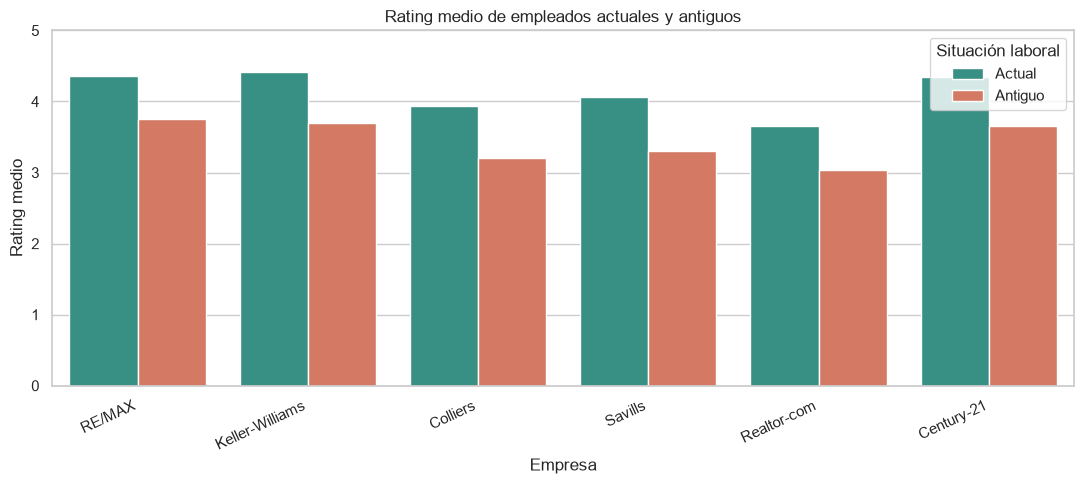

In [7]:
import seaborn as sns

sns.set_theme(style='whitegrid')

datos_rating_situacion = (
    df.groupby(['firm', 'situacion'], observed=True)
      .agg(
          rating_medio=('overall_rating', 'mean'),
          n_reseñas=('overall_rating', 'size'),
      )
      .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=datos_rating_situacion,
    x='firm',
    y='rating_medio',
    hue='situacion',
    order=FIRMS,
    hue_order=['Actual', 'Antiguo'],
    palette={'Actual': '#2A9D8F', 'Antiguo': '#E76F51'},
    ax=ax,
)

ax.set(
    title='Rating medio de empleados actuales y antiguos',
    xlabel='Empresa',
    ylabel='Rating medio',
    ylim=(0, 5),
)

plt.xticks(rotation=25, ha='right')
plt.legend(title='Situación laboral')
plt.tight_layout()

fig.savefig(
    IMAGES_DIR / 'rating_medio_de_empleados_actuales_y_antiguos.png',
    dpi=160,
    bbox_inches='tight',
)

plt.show()

### Empleados actuales frente a antiguos

Los empleados actuales otorgan valoraciones superiores a los antiguos en todas las
empresas, lo que confirma el sesgo de selección advertido en el enunciado.

RE/MAX obtiene un rating de 4,36 entre sus empleados actuales y de 3,75 entre los
antiguos. La diferencia es de 0,60 puntos, aproximadamente 0,10 puntos menor que la
brecha media de sus peers. Además, RE/MAX presenta la valoración más alta entre los
antiguos empleados de las seis compañías analizadas.

Este resultado constituye una señal positiva: aunque la experiencia de quienes han
abandonado la empresa es menos favorable, el deterioro es menor que en la competencia.
No obstante, la comparación relevante será identificar qué temas aparecen en los
comentarios negativos de los antiguos empleados, ya que pueden representar motivos
potenciales de salida.

### Evolución temporal del rating

In [8]:
# Evolución anual del rating por empresa
evolucion_rating = (
    df.groupby(['firm', 'anio'], observed=True)
      .agg(
          rating_medio=('overall_rating', 'mean'),
          n_reseñas=('overall_rating', 'size'),
      )
      .reset_index()
)

tabla_evolucion = (
    evolucion_rating
    .pivot(index='anio', columns='firm', values='rating_medio')
    .reindex(columns=FIRMS)
    .round(2)
)

tabla_evolucion

firm,RE/MAX,Keller-Williams,Colliers,Savills,Realtor-com,Century-21
anio,,,,,,
2018,3.87,4.07,3.29,3.55,3.46,4.00
2019,4.03,4.01,3.45,3.38,2.77,3.98
2020,4.05,4.17,3.53,3.79,3.21,4.03
2021,4.06,4.17,3.63,3.74,3.51,4.07
2022,4.21,4.13,3.60,3.91,3.50,4.11
2023,4.05,4.13,3.70,3.61,3.72,4.02


#### RE/MAX frente a los peers

In [9]:
# Comparación temporal de RE/MAX con la media de los peers
media_peers_anual = (
    evolucion_rating[evolucion_rating['firm'].isin(PEERS)]
    .groupby('anio', observed=True)['rating_medio']
    .mean()
    .rename('Media peers')
)

evolucion_remax = (
    evolucion_rating[evolucion_rating['firm'].eq(TARGET)]
    .set_index('anio')['rating_medio']
    .rename('RE/MAX')
)

comparacion_temporal = pd.concat(
    [evolucion_remax, media_peers_anual],
    axis=1,
)

comparacion_temporal['Gap RE/MAX vs. peers'] = (
    comparacion_temporal['RE/MAX'] -
    comparacion_temporal['Media peers']
)

comparacion_temporal.round(2)

,RE/MAX,Media peers,Gap RE/MAX vs. peers
anio,,,
2018,3.87,3.67,0.19
2019,4.03,3.52,0.51
2020,4.05,3.75,0.31
2021,4.06,3.82,0.23
2022,4.21,3.85,0.36
2023,4.05,3.84,0.21


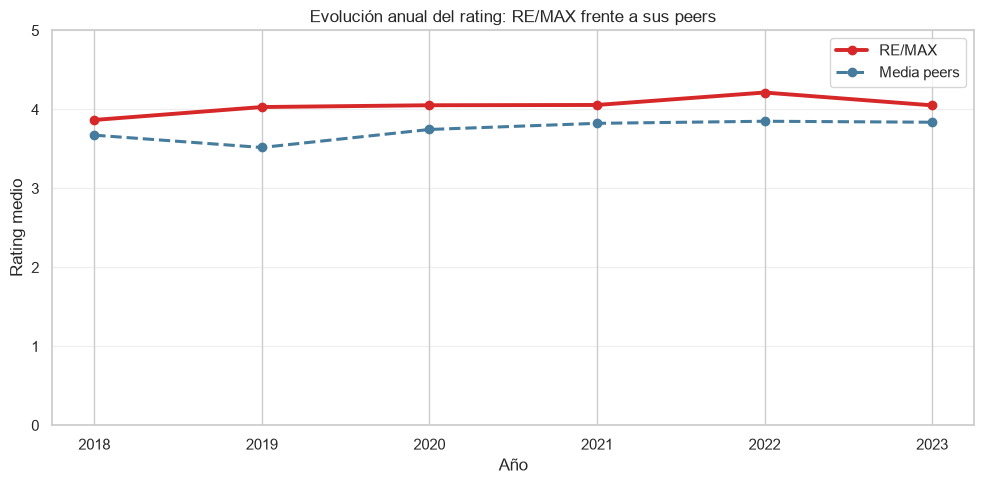

In [10]:
# Evolución anual del rating: RE/MAX frente a sus peers

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    comparacion_temporal.index,
    comparacion_temporal['RE/MAX'],
    marker='o',
    linewidth=2.8,
    color='#D62828',
    label='RE/MAX',
)

ax.plot(
    comparacion_temporal.index,
    comparacion_temporal['Media peers'],
    marker='o',
    linewidth=2.2,
    color='#457B9D',
    linestyle='--',
    label='Media peers',
)

ax.set(
    title='Evolución anual del rating: RE/MAX frente a sus peers',
    xlabel='Año',
    ylabel='Rating medio',
    ylim=(0, 5),
)

ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

fig.savefig(
    IMAGES_DIR / 'evolucion_rating_remax_vs_peers.png',
    dpi=160,
    bbox_inches='tight',
)

plt.show()

### Lectura de la evolución temporal

RE/MAX mantiene un rating superior a la media simple de sus peers durante todos los años
analizados. La ventaja anual oscila entre aproximadamente 0,19 y 0,51 puntos, por lo que
la fortaleza relativa no depende de un único periodo.

El rating de RE/MAX se mantiene estable alrededor de 4 puntos entre 2019 y 2021 y alcanza
su máximo en 2022, con 4,21. En 2023 desciende hasta 4,05, pero continúa por encima de la
media de los peers.

Los datos de 2018 y 2023 cubren años incompletos, por lo que sus variaciones deben
interpretarse con cautela. Desde la perspectiva de RRHH, convendría investigar qué
cambios o prácticas coinciden con la mejora observada en 2022 y valorar si pueden
mantenerse o extenderse.

---
## 2. Sentimiento en pros y cons

Se utiliza `distilbert-base-uncased-finetuned-sst-2-english`, un modelo transformer
preentrenado para clasificación binaria de sentimiento en inglés.

Este análisis funciona como control de calidad: dado que `pros` recoge aspectos positivos
y `cons` aspectos negativos, esperamos que la mayoría de los primeros se clasifiquen como
positivos y la mayoría de los segundos como negativos.

El modelo no dispone de una categoría neutral. Además, los textos que superen el límite
de 512 tokens se truncarán para evitar errores. Los casos discordantes se revisarán
manualmente, ya que pueden contener ironía, respuestas genéricas, ausencia de contenido
o comentarios que mezclan aspectos positivos y negativos.

In [11]:
# Carga del modelo
import torch
from transformers import pipeline
from tqdm.auto import tqdm

MODELO_SENTIMIENTO = 'distilbert-base-uncased-finetuned-sst-2-english'

if torch.backends.mps.is_available():
    DISPOSITIVO = 'mps'
elif torch.cuda.is_available():
    DISPOSITIVO = 0
else:
    DISPOSITIVO = -1

print(f'Dispositivo utilizado: {DISPOSITIVO}')

clasificador_sentimiento = pipeline(
    task='sentiment-analysis',
    model=MODELO_SENTIMIENTO,
    device=DISPOSITIVO,
)

Dispositivo utilizado: mps


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 7805.45it/s]


In [12]:
# Inferencia sobre pros y cons
def inferir_sentimiento(textos, batch_size=32):
    """Clasifica textos por lotes y devuelve etiqueta y confianza."""
    textos = textos.fillna('').astype(str).tolist()

    etiquetas = []
    confianzas = []

    for inicio in tqdm(
        range(0, len(textos), batch_size),
        desc='Clasificando sentimiento',
    ):
        lote = textos[inicio:inicio + batch_size]

        resultados = clasificador_sentimiento(
            lote,
            truncation=True,
            max_length=512,
            batch_size=batch_size,
        )

        etiquetas.extend(resultado['label'] for resultado in resultados)
        confianzas.extend(resultado['score'] for resultado in resultados)

    return etiquetas, confianzas


df['pros_sentimiento'], df['pros_confianza'] = inferir_sentimiento(df['pros'])
df['cons_sentimiento'], df['cons_confianza'] = inferir_sentimiento(df['cons'])

df[
    [
        'firm',
        'pros',
        'pros_sentimiento',
        'pros_confianza',
        'cons',
        'cons_sentimiento',
        'cons_confianza',
    ]
].head()

Clasificando sentimiento: 100%|██████████| 157/157 [00:15<00:00,  9.93it/s]


,firm,pros,pros_sentimiento,pros_confianza,cons,cons_sentimiento,cons_confianza
0,Century-21,"Flexibility, time, leadership, continuous trai...",POSITIVE,0.999455,Salary model does not apply to agents,NEGATIVE,0.999227
1,Century-21,"Easy hours, available shifts, computer work",POSITIVE,0.716582,"Pay is horrible, unorganized and no communication",NEGATIVE,0.999764
2,Century-21,"Great coworkers, keeps you busy, good management",POSITIVE,0.999874,A little crazy during holidays,NEGATIVE,0.733457
3,Century-21,good support for field agents,POSITIVE,0.999840,nothing to report as needing repair.,NEGATIVE,0.995622
4,Century-21,My specific office is very nice. We have a sal...,POSITIVE,0.999823,"At the end of the day, you have to make it hap...",NEGATIVE,0.993075


Resultado por empresa

In [13]:
# Resultado por empresa
control_sentimiento = (
    df.groupby('firm', observed=True)
      .agg(
          n_reseñas=('firm', 'size'),
          pct_pros_positivos=(
              'pros_sentimiento',
              lambda s: s.eq('POSITIVE').mean() * 100,
          ),
          pct_cons_negativos=(
              'cons_sentimiento',
              lambda s: s.eq('NEGATIVE').mean() * 100,
          ),
          confianza_media_pros=('pros_confianza', 'mean'),
          confianza_media_cons=('cons_confianza', 'mean'),
      )
      .reindex(FIRMS)
)

control_sentimiento = control_sentimiento.round({
    'pct_pros_positivos': 1,
    'pct_cons_negativos': 1,
    'confianza_media_pros': 3,
    'confianza_media_cons': 3,
})

control_sentimiento

,n_reseñas,pct_pros_positivos,pct_cons_negativos,confianza_media_pros,confianza_media_cons
firm,,,,,
RE/MAX,1000,92.6,77.7,0.990,0.970
Keller-Williams,1000,94.3,76.0,0.990,0.972
Colliers,1000,92.3,81.6,0.991,0.975
Savills,960,93.0,81.2,0.991,0.979
Realtor-com,601,88.2,80.4,0.987,0.972
Century-21,445,93.0,74.8,0.990,0.974


### Control de calidad del modelo de sentimiento

El modelo clasifica como positivos el 92,6% de los pros de RE/MAX, un resultado
prácticamente igual a la media de sus peers. Esto confirma que el modelo identifica
correctamente la orientación positiva de la mayoría de estos textos.

El porcentaje de cons clasificados como negativos es menor: 77,7% en RE/MAX y
aproximadamente 78,8% en los peers. Este resultado no implica necesariamente que el
modelo falle en uno de cada cinco casos. Algunos comentarios incluidos en `cons`
pueden indicar que no existen aspectos negativos, utilizar expresiones positivas,
contener ironía o mezclar ventajas e inconvenientes.

Las probabilidades medias son elevadas tanto en pros como en cons. Por ello, los casos
discordantes deben revisarse atendiendo al contenido y no únicamente a la confianza
del modelo.

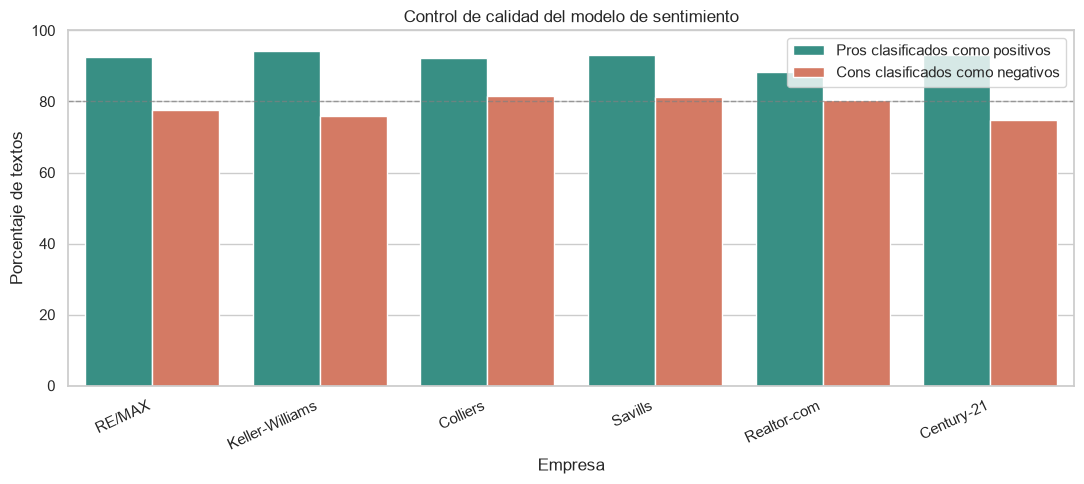

In [14]:
# Visualización del control de calidad

control_plot = (
    control_sentimiento[
        ['pct_pros_positivos', 'pct_cons_negativos']
    ]
    .rename(columns={
        'pct_pros_positivos': 'Pros clasificados como positivos',
        'pct_cons_negativos': 'Cons clasificados como negativos',
    })
    .reset_index()
    .melt(
        id_vars='firm',
        var_name='Control',
        value_name='Porcentaje',
    )
)

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=control_plot,
    x='firm',
    y='Porcentaje',
    hue='Control',
    order=FIRMS,
    palette=['#2A9D8F', '#E76F51'],
    ax=ax,
)

ax.set(
    title='Control de calidad del modelo de sentimiento',
    xlabel='Empresa',
    ylabel='Porcentaje de textos',
    ylim=(0, 100),
)

ax.axhline(80, color='gray', linestyle='--', linewidth=1, alpha=0.7)
ax.legend(title='')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()

fig.savefig(
    IMAGES_DIR / 'control_calidad_sentimiento.png',
    dpi=160,
    bbox_inches='tight',
)

plt.show()

In [15]:
# Revisión manual de discordancias entre el campo original (pros o cons)
# y el sentimiento inferido. El rating y la recomendación se muestran
# únicamente como contexto para interpretar cada caso.



def seleccionar_discordantes(
    datos,
    columna_etiqueta,
    etiqueta_discordante,
    columna_texto,
    n_target=8,
    n_por_peer=1,
):
    """Selecciona casos discordantes de RE/MAX y de cada peer."""
    casos = datos[
        datos[columna_etiqueta].eq(etiqueta_discordante)
    ].copy()

    muestra_target = casos[casos['firm'].eq(TARGET)].sample(
        n=min(n_target, casos['firm'].eq(TARGET).sum()),
        random_state=SEED,
    )

    muestras_peers = []
    for peer in PEERS:
        casos_peer = casos[casos['firm'].eq(peer)]

        if not casos_peer.empty:
            muestras_peers.append(
                casos_peer.sample(
                    n=min(n_por_peer, len(casos_peer)),
                    random_state=SEED,
                )
            )

    muestra = pd.concat(
        [muestra_target, *muestras_peers],
        ignore_index=True,
    )

    return muestra[
        [
            'firm',
            'date_review',
            'overall_rating',
            'recomienda',
            columna_texto,
            columna_etiqueta,
            columna_etiqueta.replace('sentimiento', 'confianza'),
        ]
    ]

In [16]:
# Pros clasificados como negativos

muestra_pros_negativos = seleccionar_discordantes(
    datos=df,
    columna_etiqueta='pros_sentimiento',
    etiqueta_discordante='NEGATIVE',
    columna_texto='pros',
)

with pd.option_context('display.max_colwidth', 300):
    display(muestra_pros_negativos)

,firm,date_review,overall_rating,recomienda,pros,pros_sentimiento,pros_confianza
0,RE/MAX,2018-12-04,1.0,No,"none, it would be difficult to find anything pros",NEGATIVE,0.998985
1,RE/MAX,2020-04-21,3.0,No,"Hours Were good, but it was part time",NEGATIVE,0.920868
2,RE/MAX,2019-01-31,5.0,Sí,You got a lot of leads and not many agents to compete with.,NEGATIVE,0.967484
3,RE/MAX,2019-01-14,1.0,Neutral,No pros thay one can mention,NEGATIVE,0.955975
4,RE/MAX,2020-09-01,4.0,Sí,Working on your own schedule.,NEGATIVE,0.977128
5,RE/MAX,2023-02-14,3.0,Neutral,Not flexible in work hours No over time offered,NEGATIVE,0.999255
6,RE/MAX,2021-08-26,4.0,Neutral,Make your own schedule days,NEGATIVE,0.663606
7,RE/MAX,2020-11-06,3.0,Sí,"Good but not perfect, should be better",NEGATIVE,0.975849
8,Keller-Williams,2021-04-27,3.0,Neutral,Pay scale for realtor commission,NEGATIVE,0.801419
9,Colliers,2020-07-24,1.0,No,Female upper management - very dismissive of sexual and physical harassment.,NEGATIVE,0.999578


In [17]:
# Cons clasificados como positivos

muestra_cons_positivos = seleccionar_discordantes(
    datos=df,
    columna_etiqueta='cons_sentimiento',
    etiqueta_discordante='POSITIVE',
    columna_texto='cons',
)

with pd.option_context('display.max_colwidth', 300):
    display(muestra_cons_positivos)

,firm,date_review,overall_rating,recomienda,cons,cons_sentimiento,cons_confianza
0,RE/MAX,2020-11-13,5.0,Sí,No Cons that i can think of,POSITIVE,0.996827
1,RE/MAX,2022-01-07,4.0,Neutral,Doing business there is quite expensive.,POSITIVE,0.955080
2,RE/MAX,2019-08-16,4.0,Neutral,Very high fees Splits for new agents are in their favor,POSITIVE,0.695837
3,RE/MAX,2021-08-30,5.0,Sí,I haven't had any negative experiences with the company,POSITIVE,0.996141
4,RE/MAX,2021-05-10,5.0,Sí,"WE WORK AT THE REMAX YES FRANCISHING IN Paço de Arcos WHERE IS A VERY GOOD PLACE TO WORK; THERES A LOT OF INFORMACION, COLLEGUEES ARE FASTÁTIC AND THE BROOKER IS AN AMAZING PERSON.",POSITIVE,0.999841
5,RE/MAX,2022-08-11,4.0,Sí,If you are a new/newer agent this is not the Brokerage to come to if you need a lot of training and extra help to get you started in your real estate career. If you are a self starter and do not need that then you will be just fine. I knew how to find what I needed and who to talk to for support.,POSITIVE,0.999376
6,RE/MAX,2021-08-31,5.0,Sí,being a realtor sometimes takes a lot of Family time... be sure to learn to balance both,POSITIVE,0.928472
7,RE/MAX,2020-12-29,5.0,Neutral,Not a thing is wrong here,POSITIVE,0.997968
8,Keller-Williams,2018-12-28,5.0,Sí,Work to Build Your Own Brand,POSITIVE,0.998598
9,Colliers,2023-02-22,4.0,Sí,"Expensive benefits, demanding partners, return to office",POSITIVE,0.948238


### Revisión manual de los casos discordantes

La revisión manual muestra que las discordancias no se deben exclusivamente a errores
del transformer.

Entre los pros clasificados como negativos aparecen respuestas que indican explícitamente
que no existe ninguna ventaja, críticas introducidas en el campo incorrecto y textos
mixtos en los que una ventaja va acompañada de una limitación. También se observan algunos
falsos negativos en frases breves sobre autonomía horaria o disponibilidad de leads.

Entre los cons clasificados como positivos predominan expresiones que niegan la existencia
de inconvenientes, como “No cons” o “I haven't had any negative experiences”. También
aparecen comentarios positivos introducidos en el campo equivocado y textos que combinan
una crítica con una valoración favorable. Existen algunos falsos positivos reales,
especialmente en comentarios breves sobre costes y comisiones.

Por tanto, los porcentajes obtenidos son adecuados como control de calidad, pero no deben
interpretarse como una medición exacta del sentimiento. La posición del texto en `pros`
o `cons`, la negación y el contexto aportan información que un clasificador binario puede
no representar correctamente. Se conservarán todos los textos para el modelado de topics,
sin eliminar automáticamente los casos discordantes.

___
## 3. Topic modeling 

### Decisiones metodológicas

Se utiliza BERTopic porque combina embeddings semánticos con reducción de dimensionalidad
y clustering, lo que permite detectar temas incluso cuando las reseñas utilizan palabras
diferentes para expresar una misma idea.

Los embeddings se generan con `all-MiniLM-L6-v2`, un modelo ligero para inglés que
representa cada texto mediante un vector de 384 dimensiones. Su menor coste computacional
permite ejecutar el análisis localmente sin renunciar a una representación semántica.

Se entrenan exactamente dos modelos:

1. Un único modelo conjunto con los pros de RE/MAX y todos sus peers.
2. Un único modelo conjunto con los cons de RE/MAX y todos sus peers.

No se entrena un modelo independiente por empresa, porque sus identificadores de topic
no serían comparables.

HDBSCAN puede asignar el topic `-1` a los textos que no encajan de forma suficientemente
clara en ningún grupo. Estos textos se conservarán como `Sin asignar` y se incluirán en
el denominador de los porcentajes. De esta forma, una empresa con más outliers no verá
inflado artificialmente el peso de los topics asignados. La categoría `Sin asignar` se
mostrará como control de calidad, pero no se considerará una categoría de negocio ni se
utilizará en la matriz final de priorización.

In [18]:
# Configuración y embedding de los textos para el modelado de topics con BERTopic

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

if torch.backends.mps.is_available():
    DISPOSITIVO_EMBEDDINGS = 'mps'
elif torch.cuda.is_available():
    DISPOSITIVO_EMBEDDINGS = 'cuda'
else:
    DISPOSITIVO_EMBEDDINGS = 'cpu'

MODELO_EMBEDDINGS = 'sentence-transformers/all-MiniLM-L6-v2'

print(f'Dispositivo para embeddings: {DISPOSITIVO_EMBEDDINGS}')

modelo_embeddings = SentenceTransformer(
    MODELO_EMBEDDINGS,
    device=DISPOSITIVO_EMBEDDINGS,
)

# Longitud suficiente para estos textos y razonable para la ejecución local.
modelo_embeddings.max_seq_length = 256

documentos_pros = df['pros'].fillna('').astype(str).str.strip().tolist()
documentos_cons = df['cons'].fillna('').astype(str).str.strip().tolist()

print(f'Pros: {len(documentos_pros):,}')
print(f'Cons: {len(documentos_cons):,}')

Dispositivo para embeddings: mps


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8806.35it/s]


Pros: 5,006
Cons: 5,006


### Generación y almacenamiento de embeddings
Esta celda guarda los vectores para no tener que recalcularlos si reiniciamos el kernel

In [19]:
# Ruta compatible con notebooks/, raíz del proyecto y Google Colab
MODELS_DIR = (
    Path('../models')
    if Path('../data').exists()
    else Path('models')
)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RUTA_EMBEDDINGS_PROS = MODELS_DIR / 'embeddings_pros.npy'
RUTA_EMBEDDINGS_CONS = MODELS_DIR / 'embeddings_cons.npy'

if (
    RUTA_EMBEDDINGS_PROS.exists()
    and RUTA_EMBEDDINGS_CONS.exists()
):
    embeddings_pros = np.load(RUTA_EMBEDDINGS_PROS)
    embeddings_cons = np.load(RUTA_EMBEDDINGS_CONS)

    if (
        len(embeddings_pros) != len(documentos_pros)
        or len(embeddings_cons) != len(documentos_cons)
    ):
        raise ValueError(
            'Los embeddings guardados no corresponden con la muestra actual.'
        )

    print('Embeddings cargados desde disco.')

else:
    embeddings_pros = modelo_embeddings.encode(
        documentos_pros,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    embeddings_cons = modelo_embeddings.encode(
        documentos_cons,
        batch_size=64,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    np.save(RUTA_EMBEDDINGS_PROS, embeddings_pros)
    np.save(RUTA_EMBEDDINGS_CONS, embeddings_cons)

    print('Embeddings calculados y guardados.')

print('Forma pros:', embeddings_pros.shape)
print('Forma cons:', embeddings_cons.shape)

Embeddings cargados desde disco.
Forma pros: (5006, 384)
Forma cons: (5006, 384)


Configuración BERTopic

In [20]:
def crear_modelo_bertopic():
    """Crea una instancia independiente y reproducible de BERTopic."""
    umap_model = UMAP(
        n_neighbors=15,
        n_components=5,
        min_dist=0.0,
        metric='cosine',
        random_state=SEED,
    )

    hdbscan_model = HDBSCAN(
        min_cluster_size=40,
        min_samples=10,
        metric='euclidean',
        cluster_selection_method='eom',
        prediction_data=True,
    )

    vectorizer_model = CountVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        min_df=5,
    )

    return BERTopic(
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        top_n_words=10,
        calculate_probabilities=False,
        verbose=True,
    )

La elección de min_cluster_size=40 evita generar microtopics difíciles de interpretar para RRHH, pero permite detectar categorías con un peso cercano al 1% de la muestra.

Entrenamiento conjunto

In [21]:
# Un modelo conjunto para los pros de todas las empresas
modelo_topics_pros = crear_modelo_bertopic()

topics_pros, _ = modelo_topics_pros.fit_transform(
    documentos_pros,
    embeddings_pros,
)

df['topic_pros'] = topics_pros

print('Modelo de pros completado.')

2026-10-06 20:26:45,692 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-06 20:26:59,537 - BERTopic - Dimensionality - Completed ✓
2026-10-06 20:26:59,537 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-06 20:26:59,617 - BERTopic - Cluster - Completed ✓
2026-10-06 20:26:59,619 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-06 20:26:59,663 - BERTopic - Representation - Completed ✓


Modelo de pros completado.


In [22]:
# Un modelo conjunto para los cons de todas las empresas
modelo_topics_cons = crear_modelo_bertopic()

topics_cons, _ = modelo_topics_cons.fit_transform(
    documentos_cons,
    embeddings_cons,
)

df['topic_cons'] = topics_cons

print('Modelo de cons completado.')

2026-10-06 20:26:59,715 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-06 20:27:04,725 - BERTopic - Dimensionality - Completed ✓
2026-10-06 20:27:04,725 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-06 20:27:04,792 - BERTopic - Cluster - Completed ✓
2026-10-06 20:27:04,793 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-06 20:27:04,841 - BERTopic - Representation - Completed ✓


Modelo de cons completado.


UMAP y HDBSCAN se ejecutarán principalmente en CPU, aunque los embeddings se hayan generado con MPS.

Diagnóstico inicial de los topics

In [23]:
def diagnostico_topics(modelo, topics, nombre):
    informacion = modelo.get_topic_info().copy()

    n_topics = informacion['Topic'].ne(-1).sum()
    pct_outliers = np.mean(np.asarray(topics) == -1) * 100

    print(f'Modelo: {nombre}')
    print(f'Topics identificados, sin contar -1: {n_topics}')
    print(f'Porcentaje sin asignar: {pct_outliers:.1f}%')

    display(
        informacion[
            ['Topic', 'Count', 'Name', 'Representation']
        ].head(20)
    )

    return informacion


info_topics_pros = diagnostico_topics(
    modelo_topics_pros,
    topics_pros,
    'Pros',
)

info_topics_cons = diagnostico_topics(
    modelo_topics_cons,
    topics_cons,
    'Cons',
)

Modelo: Pros
Topics identificados, sin contar -1: 30
Porcentaje sin asignar: 28.8%


,Topic,Count,Name,Representation
0,-1,1442,-1_good_company_environment_great,"[good, company, environment, great, work, peop..."
1,0,310,0_hours_flexible_schedule_flexible hours,"[hours, flexible, schedule, flexible hours, fl..."
2,1,262,1_benefits_pay_salary_bonus,"[benefits, pay, salary, bonus, good, money, de..."
3,2,260,2_culture_company culture_great culture_cultur...,"[culture, company culture, great culture, cult..."
4,3,256,3_team_great team_good team_collaborative,"[team, great team, good team, collaborative, t..."
5,4,249,4_training_great training_good training_traini...,"[training, great training, good training, trai..."
6,5,226,5_estate_real estate_real_keller,"[estate, real estate, real, keller, training, ..."
7,6,171,6_agents_new agents_new_agent,"[agents, new agents, new, agent, training new,..."
8,7,127,7_balance_work life_life_life balance,"[balance, work life, life, life balance, workl..."
9,8,127,8_brand_recognition_brand recognition_marketing,"[brand, recognition, brand recognition, market..."


Modelo: Cons
Topics identificados, sin contar -1: 25
Porcentaje sin asignar: 20.1%


,Topic,Count,Name,Representation
0,-1,1006,-1_team_company_work_management,"[team, company, work, management, like, people..."
1,0,717,0_management_culture_staff_leadership,"[management, culture, staff, leadership, lack,..."
2,1,563,1_salary_pay_low_benefits,"[salary, pay, low, benefits, low pay, lower, b..."
3,2,468,2_hours_long_long hours_work,"[hours, long, long hours, work, time, working ..."
4,3,189,3_cons_think_dont cons_dont,"[cons, think, dont cons, dont, far, really, mo..."
5,4,172,4_agents_new agents_new_agent,"[agents, new agents, new, agent, mentorship, f..."
6,5,171,5_estate_real estate_real_realtors,"[estate, real estate, real, realtors, realtorc..."
7,6,169,6_commission_commission based_based_100,"[commission, commission based, based, 100, sal..."
8,7,168,7_think_moment_far_come,"[think, moment, far, come, really, come mind, ..."
9,8,136,8_growth_room_career_opportunities,"[growth, room, career, opportunities, room gro..."


### Diagnóstico inicial de BERTopic

El modelo de pros identifica 30 topics y deja sin asignar el 28,8% de los textos.
El modelo de cons identifica 25 topics, con un 20,1% de textos sin asignar.

Aunque el porcentaje de outliers es relevante, los topics principales muestran una
interpretación semántica clara. En los pros aparecen temas relacionados con flexibilidad,
compensación, cultura, equipo, formación, conciliación, marca, liderazgo y desarrollo
profesional. En los cons aparecen dirección, remuneración, jornadas, formación de nuevos
agentes, comisiones, costes, carrera, tecnología y entorno de oficina.

Se conservarán los outliers como `Sin asignar` y no se forzará su incorporación a un
topic. Esta decisión prioriza la precisión de las categorías de negocio frente a una
cobertura artificialmente elevada.

Algunos clusters representan respuestas como “no tengo inconvenientes” o textos sin
contenido suficiente. Estos se agruparán posteriormente en `Sin contenido informativo`
y se excluirán de la interpretación de fortalezas, problemas y prioridades de RRHH,
aunque se mantendrán en el denominador de los porcentajes.

Comprobar los outliers por empresa
Antes del etiquetado debemos verificar que los outliers no se concentran especialmente en una compañía:

In [24]:
outliers_por_empresa = (
    df.assign(
        pros_sin_asignar=df['topic_pros'].eq(-1),
        cons_sin_asignar=df['topic_cons'].eq(-1),
    )
    .groupby('firm', observed=True)
    .agg(
        n_reseñas=('firm', 'size'),
        pct_pros_sin_asignar=(
            'pros_sin_asignar',
            lambda s: s.mean() * 100,
        ),
        pct_cons_sin_asignar=(
            'cons_sin_asignar',
            lambda s: s.mean() * 100,
        ),
    )
    .reindex(FIRMS)
    .round(1)
)

outliers_por_empresa

,n_reseñas,pct_pros_sin_asignar,pct_cons_sin_asignar
firm,,,
RE/MAX,1000,23.6,17.4
Keller-Williams,1000,27.2,20.6
Colliers,1000,30.5,21.2
Savills,960,34.8,22.4
Realtor-com,601,29.3,21.6
Century-21,445,26.7,15.5


#### Preparar la revisión manual de todos los topics
Para etiquetarlos correctamente necesitamos palabras clave y textos representativos, no solo el nombre automático. Creamos la función que nos ayudará a determinarlos

In [25]:
def crear_tabla_revision_topics(modelo, informacion, tipo):
    """Crea una tabla con palabras clave y ejemplos representativos."""
    filas = []

    for _, registro in informacion.iterrows():
        topic = int(registro['Topic'])

        if topic == -1:
            continue

        palabras_topic = modelo.get_topic(topic) or []
        palabras = ', '.join(
            palabra for palabra, _ in palabras_topic[:10]
        )

        ejemplos = modelo.get_representative_docs(topic) or []
        ejemplos_limpios = [
            re.sub(r'\s+', ' ', str(texto)).strip()[:250]
            for texto in ejemplos[:3]
        ]

        filas.append({
            'tipo': tipo,
            'topic': topic,
            'n_textos': int(registro['Count']),
            'nombre_automatico': registro['Name'],
            'palabras_clave': palabras,
            'ejemplo_1': ejemplos_limpios[0] if len(ejemplos_limpios) > 0 else '',
            'ejemplo_2': ejemplos_limpios[1] if len(ejemplos_limpios) > 1 else '',
            'ejemplo_3': ejemplos_limpios[2] if len(ejemplos_limpios) > 2 else '',
        })

    return pd.DataFrame(filas)


revision_topics_pros = crear_tabla_revision_topics(
    modelo_topics_pros,
    info_topics_pros,
    'Pros',
)

revision_topics_cons = crear_tabla_revision_topics(
    modelo_topics_cons,
    info_topics_cons,
    'Cons',
)

In [26]:
OUTPUTS_DIR = (
    Path('../outputs')
    if Path('../outputs').exists()
    else Path('outputs')
)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

revision_topics_pros.to_csv(
    OUTPUTS_DIR / 'revision_topics_pros.csv',
    index=False,
)

revision_topics_cons.to_csv(
    OUTPUTS_DIR / 'revision_topics_cons.csv',
    index=False,
)

print('Archivos guardados:')
print(OUTPUTS_DIR / 'revision_topics_pros.csv')
print(OUTPUTS_DIR / 'revision_topics_cons.csv')

Archivos guardados:
../outputs/revision_topics_pros.csv
../outputs/revision_topics_cons.csv


In [27]:
# Mostramos las tablas guardadas.

with pd.option_context(
    'display.max_rows', 40,
    'display.max_colwidth', 180,
):
    display(revision_topics_pros)
    display(revision_topics_cons)

,tipo,topic,n_textos,nombre_automatico,palabras_clave,ejemplo_1,ejemplo_2,ejemplo_3
0,Pros,0,310,0_hours_flexible_schedule_flexible hours,"hours, flexible, schedule, flexible hours, flexible schedule, home, work home, work, boss, freedom",Flexible Hours Could work from home or in office,Flexible hours for a school schedule,"work from home, flexible hours"
1,Pros,1,262,1_benefits_pay_salary_bonus,"benefits, pay, salary, bonus, good, money, decent, good pay, good salary, great benefits",Good pay and good benefits,The benefits and pay are decent.,Benefits are terrific. Pay seems to be normal.
2,Pros,2,260,2_culture_company culture_great culture_culture great,"culture, company culture, great culture, culture great, good culture, culture good, great, great people, balance, good",Great diversity and company culture,"Nothing, the culture is toxic",Great ethos and culture
3,Pros,3,256,3_team_great team_good team_collaborative,"team, great team, good team, collaborative, teams, team good, team great, team environment, team work, great","Good team, consistent work flow",You get to work independently while being in a “team”,The team is versatile and good.
4,Pros,4,249,4_training_great training_good training_training support,"training, great training, good training, training support, support, great, training great, training good, lots training, lots",Training training training training training,Training alike to receiving an MBA,Training is above and beyond
5,Pros,5,226,5_estate_real estate_real_keller,"estate, real estate, real, keller, training, business, industry, agents, company, new",Globally dominant real estate company,Real Estate is very good,This is a great real estate company
6,Pros,6,171,6_agents_new agents_new_agent,"agents, new agents, new, agent, training new, training, great training, great, help, program",Great training for new agents,Great agents still with them,Great Agents that always take up for others.
7,Pros,7,127,7_balance_work life_life_life balance,"balance, work life, life, life balance, worklife balance, worklife, work, balance good, good work, balance great",Mostly Good work life balance,Good work-life balance and well stocked fridge,Work life balance is enforced
8,Pros,8,127,8_brand_recognition_brand recognition_marketing,"brand, recognition, brand recognition, marketing, known, strong, franchise, national, recognized, global",brand recognition and great initial support,some marketing and brand recognition,Recognizable brand identity behind you.
9,Pros,9,126,9_people_people work_nice people_nice,"people, people work, nice people, nice, good people, great people, people nice, work, work good, people friendly",Nice people to work with,nice people to work with,Nice people to work with


,tipo,topic,n_textos,nombre_automatico,palabras_clave,ejemplo_1,ejemplo_2,ejemplo_3
0,Cons,0,717,0_management_culture_staff_leadership,"management, culture, staff, leadership, lack, turnover, employees, toxic, team, hr",lack of communication from management to staff,"-Private school boy's club culture -Depending on which team you are in, bullying/harassment often occurs. Particularly in the Residential property team, it has become very toxi...","- TOXIC work culture. Upper management does not listen and/or care. - Harassment is reported and then ""swept under the rug"". Discipline at worst is a ""slap on the hand"". Any ot..."
1,Cons,1,563,1_salary_pay_low_benefits,"salary, pay, low, benefits, low pay, lower, base, bonus, salaries, compensation",The pay for admins was very low,Low salary for the amount of work you do.,low Salary as per designation.
2,Cons,2,468,2_hours_long_long hours_work,"hours, long, long hours, work, time, working hours, working, overtime, stressful, workload",Long hours - but my choice,you have to work long hours,Long hours That is all
3,Cons,3,189,3_cons_think_dont cons_dont,"cons, think, dont cons, dont, far, really, moment, pros, experience, list",There are not cons at all,There are not many cons,nothing in the cons till now
4,Cons,4,172,4_agents_new agents_new_agent,"agents, new agents, new, agent, mentorship, fees, rude, training, classes, business",Some Agents are not seasoned,Too many agents not enough inventory,Some of the agents are arrogant a*holes.
5,Cons,5,171,5_estate_real estate_real_realtors,"estate, real estate, real, realtors, realtorcom, market, agent, business, agents, make",Real estate subject to market volatility,Real Estate Cycles a lot,Real estate agents are always on the clock and are at the mercy of the real estate market.
6,Cons,6,169,6_commission_commission based_based_100,"commission, commission based, based, 100, salary, commissions, pay, money, make, structure",They keep too much of your commission,they take 28% of your commission,Commission based only I want something with both salary and commission.
7,Cons,7,168,7_think_moment_far_come,"think, moment, far, come, really, come mind, mind, mention, non, havent",None that I can think of,None that I can think of,None that I can think of.
8,Cons,8,136,8_growth_room_career_opportunities,"growth, room, career, opportunities, room growth, progression, opportunity, grow, growth opportunities, advancement",not much room for growth,No room For growth at All,Not enough room for career growth
9,Cons,9,134,9_fees_expensive_monthly_high,"fees, expensive, monthly, high, desk, desk fees, fee, monthly fees, high fees, month",Take your Fees and do nothing.,Fees can be kinda expensive,"many fees, desk fees, paper fees, etc"


### Distribución de los textos sin asignar

RE/MAX presenta un 23,6% de outliers en pros y un 17,4% en cons. Ambos porcentajes
son inferiores a los observados en la mayoría de los peers, por lo que el modelo no
parece tener una dificultad especial para interpretar sus reseñas.

Savills presenta el porcentaje más elevado de pros sin asignar, con un 34,8%. Para
evitar que las diferencias de cobertura distorsionen la comparación, los porcentajes
de las categorías se calcularán sobre el total de reseñas de cada empresa, incluyendo
`Sin asignar` en el denominador.

Los outliers se conservarán para mantener la trazabilidad, pero no se utilizarán como
evidencia de una fortaleza o un problema de RRHH.

---
## 4. Interpretación temática y comparación con los peers

### Mapeo manual a categorías de negocio

In [28]:
CULTURA = 'Cultura, liderazgo y equipo'
FLEXIBILIDAD = 'Flexibilidad, conciliación y carga de trabajo'
COMPENSACION = 'Compensación, comisiones y costes'
FORMACION = 'Formación, onboarding y soporte'
CARRERA = 'Carrera y desarrollo'
MARCA = 'Marca y reputación'
VENTAS = 'Ventas, clientes y captación'
TECNOLOGIA = 'Tecnología, herramientas y procesos'
OFICINAS = 'Oficinas y entorno físico'
MODELO_NEGOCIO = 'Modelo de negocio y mercado'
ESTRUCTURA = 'Estructura y organización'
GENERAL = 'Valoración general sin detalle'
SIN_CONTENIDO = 'Sin contenido informativo'
SIN_ASIGNAR = 'Sin asignar'

In [29]:
# Mapeo de Pros

MAPEO_TOPICS_PROS = {
    -1: SIN_ASIGNAR,
    0: FLEXIBILIDAD,
    1: COMPENSACION,
    2: CULTURA,
    3: CULTURA,
    4: FORMACION,
    5: MARCA,
    6: FORMACION,
    7: FLEXIBILIDAD,
    8: MARCA,
    9: CULTURA,
    10: GENERAL,
    11: CULTURA,
    12: OFICINAS,
    13: CARRERA,
    14: CULTURA,
    15: FORMACION,
    16: COMPENSACION,
    17: GENERAL,
    18: CULTURA,
    19: CARRERA,
    20: FLEXIBILIDAD,
    21: GENERAL,
    22: MARCA,
    23: CULTURA,
    24: SIN_CONTENIDO,
    25: CULTURA,
    26: VENTAS,
    27: MARCA,
    28: TECNOLOGIA,
    29: GENERAL,
}

In [30]:
# Mapeo de Cons

MAPEO_TOPICS_CONS = {
    -1: SIN_ASIGNAR,
    0: CULTURA,
    1: COMPENSACION,
    2: FLEXIBILIDAD,
    3: SIN_CONTENIDO,
    4: FORMACION,
    5: MODELO_NEGOCIO,
    6: COMPENSACION,
    7: SIN_CONTENIDO,
    8: CARRERA,
    9: COMPENSACION,
    10: VENTAS,
    11: SIN_CONTENIDO,
    12: ESTRUCTURA,
    13: COMPENSACION,
    14: OFICINAS,
    15: TECNOLOGIA,
    16: COMPENSACION,
    17: SIN_CONTENIDO,
    18: FORMACION,
    19: VENTAS,
    20: SIN_CONTENIDO,
    21: SIN_CONTENIDO,
    22: SIN_CONTENIDO,
    23: SIN_CONTENIDO,
    24: FLEXIBILIDAD,
}

In [31]:
# Validación y asignación de categorías a los topics


topics_pros_observados = set(df['topic_pros'].unique())
topics_cons_observados = set(df['topic_cons'].unique())

topics_pros_sin_mapear = (
    topics_pros_observados - set(MAPEO_TOPICS_PROS)
)
topics_cons_sin_mapear = (
    topics_cons_observados - set(MAPEO_TOPICS_CONS)
)

assert not topics_pros_sin_mapear, (
    f'Topics de pros sin mapear: {topics_pros_sin_mapear}'
)
assert not topics_cons_sin_mapear, (
    f'Topics de cons sin mapear: {topics_cons_sin_mapear}'
)

df['categoria_pros'] = df['topic_pros'].map(MAPEO_TOPICS_PROS)
df['categoria_cons'] = df['topic_cons'].map(MAPEO_TOPICS_CONS)

assert df['categoria_pros'].notna().all()
assert df['categoria_cons'].notna().all()

print('Todos los topics han sido asignados a una categoría.')

Todos los topics han sido asignados a una categoría.


In [32]:
# Revisión visual del mapeo de topics a categorías

revision_mapeo_pros = (
    revision_topics_pros[
        ['topic', 'n_textos', 'palabras_clave', 'ejemplo_1']
    ]
    .assign(
        categoria=lambda x: x['topic'].map(MAPEO_TOPICS_PROS)
    )
    [['topic', 'n_textos', 'categoria', 'palabras_clave', 'ejemplo_1']]
)

revision_mapeo_cons = (
    revision_topics_cons[
        ['topic', 'n_textos', 'palabras_clave', 'ejemplo_1']
    ]
    .assign(
        categoria=lambda x: x['topic'].map(MAPEO_TOPICS_CONS)
    )
    [['topic', 'n_textos', 'categoria', 'palabras_clave', 'ejemplo_1']]
)

with pd.option_context(
    'display.max_rows', 40,
    'display.max_colwidth', 160,
):
    display(revision_mapeo_pros)
    display(revision_mapeo_cons)

,topic,n_textos,categoria,palabras_clave,ejemplo_1
0,0,310,"Flexibilidad, conciliación y carga de trabajo","hours, flexible, schedule, flexible hours, flexible schedule, home, work home, work, boss, freedom",Flexible Hours Could work from home or in office
1,1,262,"Compensación, comisiones y costes","benefits, pay, salary, bonus, good, money, decent, good pay, good salary, great benefits",Good pay and good benefits
2,2,260,"Cultura, liderazgo y equipo","culture, company culture, great culture, culture great, good culture, culture good, great, great people, balance, good",Great diversity and company culture
3,3,256,"Cultura, liderazgo y equipo","team, great team, good team, collaborative, teams, team good, team great, team environment, team work, great","Good team, consistent work flow"
4,4,249,"Formación, onboarding y soporte","training, great training, good training, training support, support, great, training great, training good, lots training, lots",Training training training training training
5,5,226,Marca y reputación,"estate, real estate, real, keller, training, business, industry, agents, company, new",Globally dominant real estate company
6,6,171,"Formación, onboarding y soporte","agents, new agents, new, agent, training new, training, great training, great, help, program",Great training for new agents
7,7,127,"Flexibilidad, conciliación y carga de trabajo","balance, work life, life, life balance, worklife balance, worklife, work, balance good, good work, balance great",Mostly Good work life balance
8,8,127,Marca y reputación,"brand, recognition, brand recognition, marketing, known, strong, franchise, national, recognized, global",brand recognition and great initial support
9,9,126,"Cultura, liderazgo y equipo","people, people work, nice people, nice, good people, great people, people nice, work, work good, people friendly",Nice people to work with


,topic,n_textos,categoria,palabras_clave,ejemplo_1
0,0,717,"Cultura, liderazgo y equipo","management, culture, staff, leadership, lack, turnover, employees, toxic, team, hr",lack of communication from management to staff
1,1,563,"Compensación, comisiones y costes","salary, pay, low, benefits, low pay, lower, base, bonus, salaries, compensation",The pay for admins was very low
2,2,468,"Flexibilidad, conciliación y carga de trabajo","hours, long, long hours, work, time, working hours, working, overtime, stressful, workload",Long hours - but my choice
3,3,189,Sin contenido informativo,"cons, think, dont cons, dont, far, really, moment, pros, experience, list",There are not cons at all
4,4,172,"Formación, onboarding y soporte","agents, new agents, new, agent, mentorship, fees, rude, training, classes, business",Some Agents are not seasoned
5,5,171,Modelo de negocio y mercado,"estate, real estate, real, realtors, realtorcom, market, agent, business, agents, make",Real estate subject to market volatility
6,6,169,"Compensación, comisiones y costes","commission, commission based, based, 100, salary, commissions, pay, money, make, structure",They keep too much of your commission
7,7,168,Sin contenido informativo,"think, moment, far, come, really, come mind, mind, mention, non, havent",None that I can think of
8,8,136,Carrera y desarrollo,"growth, room, career, opportunities, room growth, progression, opportunity, grow, growth opportunities, advancement",not much room for growth
9,9,134,"Compensación, comisiones y costes","fees, expensive, monthly, high, desk, desk fees, fee, monthly fees, high fees, month",Take your Fees and do nothing.


In [33]:
# Porcentaje de reseñas por categoría

ORDEN_CATEGORIAS = [
    CULTURA,
    FLEXIBILIDAD,
    COMPENSACION,
    FORMACION,
    CARRERA,
    MARCA,
    VENTAS,
    TECNOLOGIA,
    OFICINAS,
    MODELO_NEGOCIO,
    ESTRUCTURA,
    GENERAL,
    SIN_CONTENIDO,
    SIN_ASIGNAR,
]


def calcular_porcentajes_categoria(datos, columna_categoria):
    tabla = pd.crosstab(
        datos['firm'],
        datos[columna_categoria],
        normalize='index',
    ) * 100

    tabla = tabla.reindex(
        index=FIRMS,
        columns=ORDEN_CATEGORIAS,
        fill_value=0,
    )

    assert np.allclose(
        tabla.sum(axis=1),
        100,
    ), 'Los porcentajes no suman 100%.'

    return tabla.round(1)


porcentaje_categorias_pros = calcular_porcentajes_categoria(
    df,
    'categoria_pros',
)

porcentaje_categorias_cons = calcular_porcentajes_categoria(
    df,
    'categoria_cons',
)

print('Categorías en pros (% del total de reseñas):')
display(porcentaje_categorias_pros)

print('Categorías en cons (% del total de reseñas):')
display(porcentaje_categorias_cons)

Categorías en pros (% del total de reseñas):


categoria_pros,"Cultura, liderazgo y equipo","Flexibilidad, conciliación y carga de trabajo","Compensación, comisiones y costes","Formación, onboarding y soporte",Carrera y desarrollo,Marca y reputación,"Ventas, clientes y captación","Tecnología, herramientas y procesos",Oficinas y entorno físico,Modelo de negocio y mercado,Estructura y organización,Valoración general sin detalle,Sin contenido informativo,Sin asignar
firm,,,,,,,,,,,,,,
RE/MAX,14.6,13.1,6.3,10.7,3.0,16.3,1.7,1.5,1.2,0.0,0.0,7.2,0.8,23.6
Keller-Williams,14.1,7.2,3.3,25.9,2.4,11.4,0.8,1.0,1.0,0.0,0.0,4.8,0.9,27.2
Colliers,28.6,9.4,5.6,3.3,6.3,4.6,0.9,0.2,4.1,0.0,0.0,5.2,1.3,30.5
Savills,26.2,7.9,7.1,3.3,3.6,5.7,0.5,0.0,3.5,0.0,0.0,5.6,1.6,34.8
Realtor-com,20.6,13.6,15.3,1.7,2.3,6.0,1.8,0.3,0.8,0.0,0.0,6.7,1.5,29.3
Century-21,16.4,10.8,6.7,14.4,2.0,10.3,0.2,2.7,1.3,0.0,0.0,7.9,0.4,26.7


Categorías en cons (% del total de reseñas):


categoria_cons,"Cultura, liderazgo y equipo","Flexibilidad, conciliación y carga de trabajo","Compensación, comisiones y costes","Formación, onboarding y soporte",Carrera y desarrollo,Marca y reputación,"Ventas, clientes y captación","Tecnología, herramientas y procesos",Oficinas y entorno físico,Modelo de negocio y mercado,Estructura y organización,Valoración general sin detalle,Sin contenido informativo,Sin asignar
firm,,,,,,,,,,,,,,
RE/MAX,6.9,10.8,27.2,6.1,2.4,0.0,3.3,1.6,2.1,5.0,1.3,0.0,15.9,17.4
Keller-Williams,6.9,6.8,23.9,10.3,1.4,0.0,4.0,1.0,2.2,5.8,1.3,0.0,15.8,20.6
Colliers,20.8,11.4,19.1,1.2,5.0,0.0,1.4,0.9,2.2,0.5,2.4,0.0,13.9,21.2
Savills,18.9,14.0,17.7,2.0,3.0,0.0,1.8,1.1,1.9,1.0,4.1,0.0,12.2,22.4
Realtor-com,27.0,7.2,9.0,0.8,2.7,0.0,8.8,5.0,0.3,3.7,2.0,0.0,12.0,21.6
Century-21,6.3,9.2,26.1,8.3,0.7,0.0,3.1,2.0,2.0,5.8,1.1,0.0,19.8,15.5


Balance neto y gap frente a los peers

In [34]:
CATEGORIAS_NEGOCIO = [
    CULTURA,
    FLEXIBILIDAD,
    COMPENSACION,
    FORMACION,
    CARRERA,
    MARCA,
    VENTAS,
    TECNOLOGIA,
    OFICINAS,
    MODELO_NEGOCIO,
    ESTRUCTURA,
]


def calcular_porcentajes_exactos(datos, columna_categoria):
    tabla = pd.crosstab(
        datos['firm'],
        datos[columna_categoria],
        normalize='index',
    ) * 100

    return tabla.reindex(
        index=FIRMS,
        columns=ORDEN_CATEGORIAS,
        fill_value=0,
    )


porcentaje_pros_exacto = calcular_porcentajes_exactos(
    df,
    'categoria_pros',
)

porcentaje_cons_exacto = calcular_porcentajes_exactos(
    df,
    'categoria_cons',
)

media_peers_pros = porcentaje_pros_exacto.loc[PEERS].mean()
media_peers_cons = porcentaje_cons_exacto.loc[PEERS].mean()

balance_remax = (
    porcentaje_pros_exacto.loc[TARGET]
    - porcentaje_cons_exacto.loc[TARGET]
)

balance_peers = media_peers_pros - media_peers_cons

comparacion_categorias = pd.DataFrame({
    'Pros RE/MAX (%)': porcentaje_pros_exacto.loc[TARGET],
    'Cons RE/MAX (%)': porcentaje_cons_exacto.loc[TARGET],
    'Balance RE/MAX': balance_remax,
    'Pros peers (%)': media_peers_pros,
    'Cons peers (%)': media_peers_cons,
    'Balance peers': balance_peers,
})

comparacion_categorias['Gap balance vs. peers'] = (
    comparacion_categorias['Balance RE/MAX']
    - comparacion_categorias['Balance peers']
)

comparacion_negocio = (
    comparacion_categorias
    .loc[CATEGORIAS_NEGOCIO]
    .sort_values('Gap balance vs. peers', ascending=False)
)

comparacion_negocio.round(2)

,Pros RE/MAX (%),Cons RE/MAX (%),Balance RE/MAX,Pros peers (%),Cons peers (%),Balance peers,Gap balance vs. peers
Marca y reputación,16.3,0.0,16.3,7.61,0.00,7.61,8.69
"Cultura, liderazgo y equipo",14.6,6.9,7.7,21.20,15.96,5.24,2.46
"Flexibilidad, conciliación y carga de trabajo",13.1,10.8,2.3,9.79,9.71,0.08,2.22
"Ventas, clientes y captación",1.7,3.3,-1.6,0.86,3.83,-2.97,1.37
"Tecnología, herramientas y procesos",1.5,1.6,-0.1,0.85,2.01,-1.17,1.07
Estructura y organización,0.0,1.3,-1.3,0.00,2.18,-2.18,0.88
Carrera y desarrollo,3.0,2.4,0.6,3.34,2.55,0.79,-0.19
"Formación, onboarding y soporte",10.7,6.1,4.6,9.72,4.53,5.19,-0.59
Oficinas y entorno físico,1.2,2.1,-0.9,2.16,1.73,0.44,-1.34
Modelo de negocio y mercado,0.0,5.0,-5.0,0.00,3.37,-3.37,-1.63


In [35]:
# Guardamos la tabla
comparacion_negocio.to_csv(
    OUTPUTS_DIR / 'comparacion_categorias_remax_vs_peers.csv',
)

print(
    OUTPUTS_DIR /
    'comparacion_categorias_remax_vs_peers.csv'
)

../outputs/comparacion_categorias_remax_vs_peers.csv


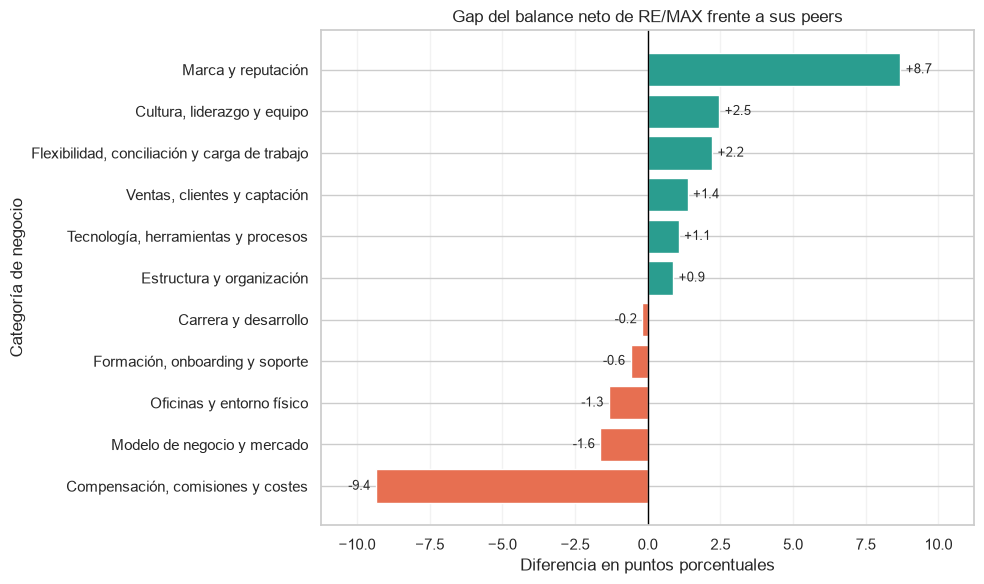

In [36]:
# Visualización del GAP competitivo de RE/MAX frente a la media de sus peers

datos_gap = (
    comparacion_negocio['Gap balance vs. peers']
    .sort_values()
)

colores = [
    '#2A9D8F' if valor >= 0 else '#E76F51'
    for valor in datos_gap
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    datos_gap.index,
    datos_gap.values,
    color=colores,
)

ax.axvline(
    0,
    color='black',
    linewidth=1,
)

ax.set(
    title='Gap del balance neto de RE/MAX frente a sus peers',
    xlabel='Diferencia en puntos porcentuales',
    ylabel='Categoría de negocio',
)

ax.bar_label(
    barras,
    labels=[f'{valor:+.1f}' for valor in datos_gap.values],
    padding=4,
    fontsize=9,
)

margen = max(abs(datos_gap.min()), abs(datos_gap.max())) * 1.2
ax.set_xlim(-margen, margen)
ax.grid(axis='x', alpha=0.25)

plt.tight_layout()

fig.savefig(
    IMAGES_DIR / 'gap_balance_remax_vs_peers.png',
    dpi=160,
    bbox_inches='tight',
)

plt.show()

### Balance neto y comparación con los peers

La principal fortaleza diferencial de RE/MAX es `Marca y reputación`. La categoría
aparece con mucha mayor frecuencia en los pros de RE/MAX que en los de sus peers y no
tiene un peso relevante en los cons. El reconocimiento de marca constituye, por tanto,
un activo claro para la atracción de talento.

RE/MAX también presenta ventajas relativas en `Cultura, liderazgo y equipo` y en
`Flexibilidad, conciliación y carga de trabajo`. Aunque ambas categorías aparecen en
los cons, su balance entre menciones positivas y negativas es más favorable que el de
la competencia.

La principal debilidad es `Compensación, comisiones y costes`. Su peso en los cons de
RE/MAX es muy superior al observado en los pros y produce una desventaja cercana a nueve
puntos porcentuales frente al balance medio de los peers. Esta diferencia es lo
suficientemente grande como para considerarla la principal candidata a la matriz de
priorización.

También aparecen desventajas menores en `Modelo de negocio y mercado`, `Oficinas y
entorno físico` y `Formación, onboarding y soporte`. Estas categorías deberán validarse
con el rating y la recomendación antes de considerarlas problemas prioritarios.

Los porcentajes son relativos y se calculan sobre el total de reseñas de cada empresa.
Por ello, la interpretación se basa en el balance neto y en la comparación con los peers,
no únicamente en el peso de una categoría dentro de los cons.

### Contraste con el rating y la recomendación

Una categoría con peso elevado en los cons no constituye necesariamente un problema
prioritario. Para validar su impacto se compara el rating medio y el porcentaje de
recomendación de las reseñas asociadas a cada categoría con los valores generales de
RE/MAX.

Si una categoría representa un problema real, esperamos que sus reseñas presenten un
rating inferior y una menor recomendación que el conjunto de la empresa. También se
compara su resultado con el obtenido por los peers para esa misma categoría.

In [37]:
df_remax = df[df['firm'].eq(TARGET)].copy()
df_peers = df[df['firm'].isin(PEERS)].copy()

rating_general_remax = df_remax['overall_rating'].mean()
recomendacion_general_remax = (
    df_remax['recomienda'].eq('Sí').mean() * 100
)

impacto_remax = (
    df_remax[
        df_remax['categoria_cons'].isin(CATEGORIAS_NEGOCIO)
    ]
    .groupby('categoria_cons', observed=True)
    .agg(
        n_reseñas=('firm', 'size'),
        rating_medio=('overall_rating', 'mean'),
        pct_recomienda=(
            'recomienda',
            lambda s: s.eq('Sí').mean() * 100,
        ),
    )
)

impacto_remax['peso_en_cons_pct'] = (
    porcentaje_cons_exacto
    .loc[TARGET]
    .reindex(impacto_remax.index)
)

impacto_remax['gap_rating_vs_total_remax'] = (
    impacto_remax['rating_medio']
    - rating_general_remax
)

impacto_remax['gap_recomendacion_vs_total_remax'] = (
    impacto_remax['pct_recomienda']
    - recomendacion_general_remax
)

impacto_remax = impacto_remax.sort_values(
    'gap_rating_vs_total_remax'
)

print(f'Rating general de RE/MAX: {rating_general_remax:.2f}')
print(
    'Recomendación general de RE/MAX: '
    f'{recomendacion_general_remax:.1f}%'
)

impacto_remax.round(2)

Rating general de RE/MAX: 4.10
Recomendación general de RE/MAX: 42.2%


,n_reseñas,rating_medio,pct_recomienda,peso_en_cons_pct,gap_rating_vs_total_remax,gap_recomendacion_vs_total_remax
categoria_cons,,,,,,
"Cultura, liderazgo y equipo",69,3.20,30.43,6.9,-0.89,-11.77
Carrera y desarrollo,24,3.79,45.83,2.4,-0.30,3.63
"Ventas, clientes y captación",33,3.82,42.42,3.3,-0.28,0.22
"Compensación, comisiones y costes",272,3.89,36.40,27.2,-0.21,-5.80
"Tecnología, herramientas y procesos",16,3.94,37.50,1.6,-0.16,-4.70
Modelo de negocio y mercado,50,4.10,50.00,5.0,0.00,7.80
Oficinas y entorno físico,21,4.14,47.62,2.1,0.05,5.42
"Formación, onboarding y soporte",61,4.20,37.70,6.1,0.10,-4.50
"Flexibilidad, conciliación y carga de trabajo",108,4.31,47.22,10.8,0.21,5.02


In [38]:
impacto_peers_por_empresa = (
    df_peers[
        df_peers['categoria_cons'].isin(CATEGORIAS_NEGOCIO)
    ]
    .groupby(
        ['firm', 'categoria_cons'],
        observed=True,
    )
    .agg(
        n_reseñas=('firm', 'size'),
        rating_medio=('overall_rating', 'mean'),
        pct_recomienda=(
            'recomienda',
            lambda s: s.eq('Sí').mean() * 100,
        ),
    )
    .reset_index()
)

# Media simple entre empresas para evitar que el peer con más
# observaciones dentro de una categoría domine el resultado.
impacto_peers = (
    impacto_peers_por_empresa
    .groupby('categoria_cons', observed=True)
    .agg(
        n_empresas_peers=('firm', 'nunique'),
        rating_medio_peers=('rating_medio', 'mean'),
        pct_recomienda_peers=('pct_recomienda', 'mean'),
    )
)

validacion_categorias = impacto_remax.join(
    impacto_peers,
    how='left',
)

validacion_categorias['gap_rating_remax_vs_peers'] = (
    validacion_categorias['rating_medio']
    - validacion_categorias['rating_medio_peers']
)

validacion_categorias['gap_recomendacion_remax_vs_peers'] = (
    validacion_categorias['pct_recomienda']
    - validacion_categorias['pct_recomienda_peers']
)

validacion_categorias.round(2)

,n_reseñas,rating_medio,pct_recomienda,peso_en_cons_pct,gap_rating_vs_total_remax,gap_recomendacion_vs_total_remax,n_empresas_peers,rating_medio_peers,pct_recomienda_peers,gap_rating_remax_vs_peers,gap_recomendacion_remax_vs_peers
categoria_cons,,,,,,,,,,,
"Cultura, liderazgo y equipo",69,3.20,30.43,6.9,-0.89,-11.77,5,2.86,23.69,0.34,6.74
Carrera y desarrollo,24,3.79,45.83,2.4,-0.30,3.63,5,3.70,43.58,0.09,2.25
"Ventas, clientes y captación",33,3.82,42.42,3.3,-0.28,0.22,5,3.75,33.50,0.07,8.93
"Compensación, comisiones y costes",272,3.89,36.40,27.2,-0.21,-5.80,5,3.78,43.87,0.11,-7.47
"Tecnología, herramientas y procesos",16,3.94,37.50,1.6,-0.16,-4.70,5,3.84,56.42,0.10,-18.92
Modelo de negocio y mercado,50,4.10,50.00,5.0,0.00,7.80,5,4.01,58.52,0.09,-8.52
Oficinas y entorno físico,21,4.14,47.62,2.1,0.05,5.42,5,4.29,65.15,-0.15,-17.53
"Formación, onboarding y soporte",61,4.20,37.70,6.1,0.10,-4.50,5,3.52,37.14,0.68,0.56
"Flexibilidad, conciliación y carga de trabajo",108,4.31,47.22,10.8,0.21,5.02,5,3.99,41.70,0.31,5.52


In [39]:
# Guardamos los resultados de la validación de categorías y su impacto en rating y recomendación

validacion_categorias.to_csv(
    OUTPUTS_DIR / 'validacion_categorias_rating_recomendacion.csv',
)

print(
    OUTPUTS_DIR /
    'validacion_categorias_rating_recomendacion.csv'
)

../outputs/validacion_categorias_rating_recomendacion.csv


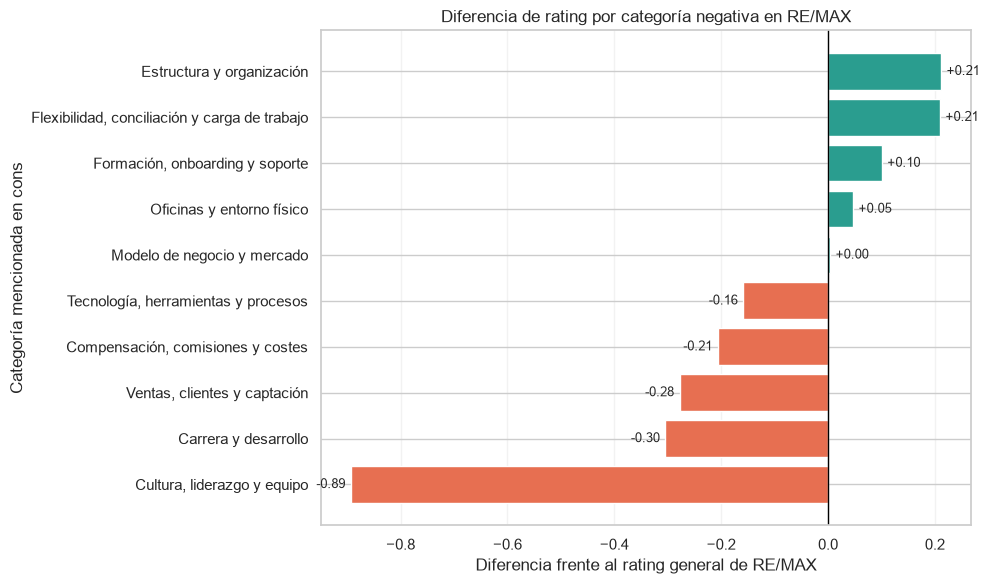

In [40]:
datos_impacto_rating = (
    impacto_remax['gap_rating_vs_total_remax']
    .sort_values()
)

colores = [
    '#E76F51' if valor < 0 else '#2A9D8F'
    for valor in datos_impacto_rating
]

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    datos_impacto_rating.index,
    datos_impacto_rating.values,
    color=colores,
)

ax.axvline(0, color='black', linewidth=1)

ax.set(
    title='Diferencia de rating por categoría negativa en RE/MAX',
    xlabel='Diferencia frente al rating general de RE/MAX',
    ylabel='Categoría mencionada en cons',
)

ax.bar_label(
    barras,
    labels=[
        f'{valor:+.2f}'
        for valor in datos_impacto_rating.values
    ],
    padding=4,
    fontsize=9,
)

ax.grid(axis='x', alpha=0.25)
plt.tight_layout()

fig.savefig(
    IMAGES_DIR / 'impacto_categorias_cons_rating_remax.png',
    dpi=160,
    bbox_inches='tight',
)

plt.show()

### Validación mediante rating y recomendación

`Compensación, comisiones y costes` queda confirmada como la principal debilidad de
RE/MAX. Es la categoría con mayor peso en los cons, presenta un balance muy inferior
al de los peers y sus reseñas tienen un rating y una recomendación inferiores a los
valores generales de la empresa. La menor recomendación frente a los peers para esta
misma categoría refuerza su relevancia competitiva.

Las quejas sobre `Cultura, liderazgo y equipo` tienen el mayor impacto sobre la
experiencia individual: su rating medio es 3,20 y solo el 30,4% recomienda la empresa.
Sin embargo, RE/MAX presenta un balance más favorable que los peers en esta categoría.
Por tanto, constituye un problema grave cuando ocurre, pero no una debilidad
diferencial frente al mercado.

Las categorías `Modelo de negocio y mercado` y `Oficinas y entorno físico` no presentan
un rating ni una recomendación inferiores al promedio de RE/MAX, por lo que no quedan
confirmadas como prioridades. `Tecnología, herramientas y procesos` muestra una menor
recomendación, pero solo contiene 16 reseñas y debe interpretarse con cautela.

`Flexibilidad, conciliación y carga de trabajo` se confirma como una fortaleza: incluso
las reseñas cuyos cons se asignan a esta categoría presentan un rating y una recomendación
superiores a la media de RE/MAX y a los resultados equivalentes de los peers.

---
## 5. Empleados actuales frente a antiguos

Los cons de los antiguos empleados se utilizan como aproximación a posibles motivos
de salida. La comparación se centra en la distribución de temas, no en el sentimiento
general, porque los antiguos empleados puntúan sistemáticamente peor en todas las
empresas.

Se realizan dos comparaciones:

1. Antiguos frente a actuales dentro de RE/MAX.
2. Antiguos de RE/MAX frente a antiguos de los peers.

In [41]:
# Distribución dentro de RE/MAX

porcentaje_cons_situacion_remax = (
    pd.crosstab(
        df_remax['situacion'],
        df_remax['categoria_cons'],
        normalize='index',
    ) * 100
)

porcentaje_cons_situacion_remax = (
    porcentaje_cons_situacion_remax
    .reindex(
        index=['Actual', 'Antiguo'],
        columns=ORDEN_CATEGORIAS,
        fill_value=0,
    )
)

porcentaje_cons_situacion_remax.round(1)

categoria_cons,"Cultura, liderazgo y equipo","Flexibilidad, conciliación y carga de trabajo","Compensación, comisiones y costes","Formación, onboarding y soporte",Carrera y desarrollo,Marca y reputación,"Ventas, clientes y captación","Tecnología, herramientas y procesos",Oficinas y entorno físico,Modelo de negocio y mercado,Estructura y organización,Valoración general sin detalle,Sin contenido informativo,Sin asignar
situacion,,,,,,,,,,,,,,
Actual,4.9,11.4,26.8,6.5,1.8,0,3.2,1.9,2.8,5.6,1.2,0,17.3,16.5
Antiguo,9.5,10.0,27.8,5.6,3.2,0,3.5,1.2,1.2,4.2,1.4,0,14.1,18.5


In [42]:
# Antiguos de RE/MAX frente a los peers

df_antiguos = df[df['situacion'].eq('Antiguo')].copy()

porcentaje_cons_antiguos_empresa = (
    pd.crosstab(
        df_antiguos['firm'],
        df_antiguos['categoria_cons'],
        normalize='index',
    ) * 100
)

porcentaje_cons_antiguos_empresa = (
    porcentaje_cons_antiguos_empresa
    .reindex(
        index=FIRMS,
        columns=ORDEN_CATEGORIAS,
        fill_value=0,
    )
)

media_antiguos_peers = (
    porcentaje_cons_antiguos_empresa
    .loc[PEERS]
    .mean()
)

analisis_antiguos = pd.DataFrame({
    'Actuales RE/MAX (%)':
        porcentaje_cons_situacion_remax.loc['Actual'],
    'Antiguos RE/MAX (%)':
        porcentaje_cons_situacion_remax.loc['Antiguo'],
    'Antiguos peers (%)':
        media_antiguos_peers,
})

analisis_antiguos['Gap antiguos vs. actuales'] = (
    analisis_antiguos['Antiguos RE/MAX (%)']
    - analisis_antiguos['Actuales RE/MAX (%)']
)

analisis_antiguos['Gap antiguos RE/MAX vs. peers'] = (
    analisis_antiguos['Antiguos RE/MAX (%)']
    - analisis_antiguos['Antiguos peers (%)']
)

analisis_antiguos_negocio = (
    analisis_antiguos
    .loc[CATEGORIAS_NEGOCIO]
    .sort_values(
        'Gap antiguos RE/MAX vs. peers',
        ascending=False,
    )
)

analisis_antiguos_negocio.round(2)

,Actuales RE/MAX (%),Antiguos RE/MAX (%),Antiguos peers (%),Gap antiguos vs. actuales,Gap antiguos RE/MAX vs. peers
categoria_cons,,,,,
"Compensación, comisiones y costes",26.76,27.78,17.62,1.02,10.16
Modelo de negocio y mercado,5.63,4.17,3.46,-1.47,0.71
"Flexibilidad, conciliación y carga de trabajo",11.44,9.95,9.55,-1.49,0.40
Carrera y desarrollo,1.76,3.24,2.97,1.48,0.27
"Formación, onboarding y soporte",6.51,5.56,5.31,-0.96,0.25
Marca y reputación,0.00,0.00,0.00,0.00,0.00
Estructura y organización,1.23,1.39,1.55,0.16,-0.16
Oficinas y entorno físico,2.82,1.16,1.38,-1.66,-0.22
"Tecnología, herramientas y procesos",1.94,1.16,1.96,-0.78,-0.80


In [43]:
# Guardamos el resultado

analisis_antiguos_negocio.to_csv(
    OUTPUTS_DIR / 'cons_antiguos_remax_vs_peers.csv',
)

print(
    OUTPUTS_DIR /
    'cons_antiguos_remax_vs_peers.csv'
)

../outputs/cons_antiguos_remax_vs_peers.csv


### Posibles motivos de salida y cambio del marco de comparación

Los antiguos empleados y asociados de RE/MAX otorgan un rating medio de 3,75, frente
a 4,36 entre quienes continúan en la compañía. Esta diferencia no implica necesariamente
que la experiencia empeore únicamente como consecuencia de abandonar RE/MAX. También
puede reflejar un cambio en el marco de referencia desde el que se evalúa la empresa.

Después de salir, un profesional puede conocer otros modelos de trabajo, estructuras de
comisiones, sistemas de soporte y procedimientos comerciales. También puede intentar
establecerse de forma independiente con una marca propia o incorporarse a una agencia
más pequeña. Estas experiencias amplían sus puntos de comparación y pueden modificar
retrospectivamente su valoración de RE/MAX en ambos sentidos.

Por un lado, trabajar fuera de una gran red puede hacer más visibles las ventajas de
RE/MAX, como el reconocimiento de marca, el acceso a formación, las herramientas
comerciales y el soporte de una estructura consolidada. Esto podría contribuir a que
RE/MAX conserve un rating relativamente elevado entre sus antiguos empleados: 3,75,
el valor más alto del grupo analizado, y una brecha entre actuales y antiguos menor que
la media de los peers.

Por otro lado, conocer modelos con menores costes, mayor autonomía o sistemas diferentes
de reparto puede hacer que las comisiones, cuotas y gastos asociados a RE/MAX se perciban
de forma más crítica. Esta interpretación es coherente con el análisis temático:
`Compensación, comisiones y costes` representa el 27,8% de los cons de antiguos empleados
de RE/MAX, aproximadamente diez puntos porcentuales más que entre los antiguos empleados
de los peers.

Las menciones a `Cultura, liderazgo y equipo` también aumentan entre los antiguos frente
a los actuales. Esto sugiere que determinadas experiencias con la dirección, el equipo
o una oficina concreta pueden intervenir en algunas salidas. Sin embargo, esta categoría
tiene mucho menos peso entre los antiguos de RE/MAX que entre los antiguos de los peers,
por lo que no constituye una debilidad competitiva general.

`Carrera y desarrollo` aumenta moderadamente entre antiguos y actuales, pero su peso es
reducido y apenas difiere del observado en los peers. Se considera una señal secundaria
que conviene monitorizar.

También debe considerarse la evolución de la propia empresa. Los empleados actuales
experimentan las políticas, herramientas, sistemas de soporte y estilos de dirección
vigentes en el momento más reciente. En cambio, parte de los antiguos empleados puede
estar valorando procesos que RE/MAX ya ha modificado o sustituido.

Si la compañía ha mejorado su formación, tecnología, comunicación o soporte al agente,
la menor valoración de los antiguos podría reflejar una etapa anterior y no representar
completamente la experiencia actual. En ese caso, comparar ambos grupos sin considerar
el momento temporal podría exagerar la magnitud de los problemas vigentes.

También podría ocurrir lo contrario: si determinados procesos se han deteriorado, los
antiguos empleados podrían conservar una percepción más favorable de una etapa previa.
Por tanto, la situación laboral puede estar relacionada con la antigüedad de la
experiencia y con la evolución organizativa de RE/MAX.

La variable `date_review` indica cuándo se publicó la reseña, pero no proporciona las
fechas exactas de entrada y salida ni permite identificar qué versión de los procesos
experimentó cada persona. En consecuencia, no es posible separar completamente el efecto
de abandonar la empresa del efecto de pertenecer a una etapa organizativa diferente.

En conjunto, las diferencias entre actuales y antiguos pueden responder a tres mecanismos:

- un sesgo de selección entre quienes permanecen y quienes salen, 
- una reevaluación posterior al conocer otras alternativas profesionales 
- y la evolución de RE/MAX a lo largo del tiempo. 

Glassdoor no sigue a las mismas personas antes y después de su salida ni identifica
con precisión los procesos que experimentaron. Por ello, estas explicaciones deben
interpretarse como hipótesis plausibles para RRHH y no como relaciones causales demostradas.

In [44]:
# Comprobación temporal complementaria
rating_anual_situacion_remax = (
    df_remax
    .groupby(['anio', 'situacion'], observed=True)
    .agg(
        n_reseñas=('overall_rating', 'size'),
        rating_medio=('overall_rating', 'mean'),
    )
    .reset_index()
)

rating_anual_situacion_remax

,anio,situacion,n_reseñas,rating_medio
0,2018,Actual,24,4.083333
1,2018,Antiguo,21,3.619048
2,2019,Actual,53,4.150943
3,2019,Antiguo,46,3.891304
4,2020,Actual,86,4.406977
5,2020,Antiguo,65,3.584615
6,2021,Actual,168,4.351190
7,2021,Antiguo,133,3.684211
8,2022,Actual,198,4.398990
9,2022,Antiguo,129,3.930233


In [45]:
brecha_anual_situacion = (
    rating_anual_situacion_remax
    .pivot(
        index='anio',
        columns='situacion',
        values='rating_medio',
    )
    .reindex(columns=['Actual', 'Antiguo'])
)

brecha_anual_situacion['Brecha actual - antiguo'] = (
    brecha_anual_situacion['Actual']
    - brecha_anual_situacion['Antiguo']
)

brecha_anual_situacion.round(2)

situacion,Actual,Antiguo,Brecha actual - antiguo
anio,,,
2018,4.08,3.62,0.46
2019,4.15,3.89,0.26
2020,4.41,3.58,0.82
2021,4.35,3.68,0.67
2022,4.40,3.93,0.47
2023,4.49,3.61,0.88


Esta comprobación controla parcialmente el año de publicación, pero no resuelve por completo el problema: una reseña publicada en 2022 por un antiguo empleado podría describir procesos vividos bastante antes. Esa limitación debe permanecer explícita.

---
## 6. Áreas de mejora y matriz de priorización

La priorización combina dos dimensiones:

- El peso de cada categoría en los cons de RE/MAX.
- La desventaja del balance neto de RE/MAX frente a los peers.

Una categoría es prioritaria cuando tiene una presencia material en los cons y, al mismo
tiempo, RE/MAX presenta un balance peor que la competencia. Como referencia operativa,
se considera material un peso mínimo del 5%, equivalente aproximadamente a 50 reseñas
en la muestra de RE/MAX.

In [46]:
# Preparación de la matriz de priorización para la toma de decisiones

matriz_priorizacion = (
    comparacion_negocio[
        [
            'Cons RE/MAX (%)',
            'Gap balance vs. peers',
        ]
    ]
    .rename(columns={
        'Cons RE/MAX (%)': 'Peso en cons RE/MAX (%)',
    })
    .copy()
)

# El gap se invierte para que un valor positivo represente desventaja.
matriz_priorizacion['Desventaja vs. peers'] = (
    -matriz_priorizacion['Gap balance vs. peers']
)

matriz_priorizacion = matriz_priorizacion.join(
    validacion_categorias[
        [
            'n_reseñas',
            'gap_rating_vs_total_remax',
            'gap_recomendacion_vs_total_remax',
        ]
    ],
    how='left',
)

matriz_priorizacion = matriz_priorizacion.sort_values(
    ['Desventaja vs. peers', 'Peso en cons RE/MAX (%)'],
    ascending=False,
)

matriz_priorizacion.round(2)

,Peso en cons RE/MAX (%),Gap balance vs. peers,Desventaja vs. peers,n_reseñas,gap_rating_vs_total_remax,gap_recomendacion_vs_total_remax
"Compensación, comisiones y costes",27.2,-9.35,9.35,272.0,-0.21,-5.80
Modelo de negocio y mercado,5.0,-1.63,1.63,50.0,0.00,7.80
Oficinas y entorno físico,2.1,-1.34,1.34,21.0,0.05,5.42
"Formación, onboarding y soporte",6.1,-0.59,0.59,61.0,0.10,-4.50
Carrera y desarrollo,2.4,-0.19,0.19,24.0,-0.30,3.63
Estructura y organización,1.3,0.88,-0.88,13.0,0.21,19.34
"Tecnología, herramientas y procesos",1.6,1.07,-1.07,16.0,-0.16,-4.70
"Ventas, clientes y captación",3.3,1.37,-1.37,33.0,-0.28,0.22
"Flexibilidad, conciliación y carga de trabajo",10.8,2.22,-2.22,108.0,0.21,5.02
"Cultura, liderazgo y equipo",6.9,2.46,-2.46,69.0,-0.89,-11.77


In [47]:
# Clasificación de las señales
def clasificar_prioridad(fila):
    peso_material = fila['Peso en cons RE/MAX (%)'] >= 5
    peor_que_peers = fila['Desventaja vs. peers'] > 0
    peor_rating = fila['gap_rating_vs_total_remax'] < 0
    menor_recomendacion = (
        fila['gap_recomendacion_vs_total_remax'] < 0
    )

    if (
        peso_material
        and peor_que_peers
        and peor_rating
        and menor_recomendacion
    ):
        return 'Prioridad alta'

    if peso_material and peor_que_peers:
        return 'Revisar'

    if (
        not peor_que_peers
        and (peor_rating or menor_recomendacion)
    ):
        return 'Problema interno, no diferencial'

    return 'No prioritaria'


matriz_priorizacion['Clasificación'] = (
    matriz_priorizacion.apply(
        clasificar_prioridad,
        axis=1,
    )
)

matriz_priorizacion.round(2)

,Peso en cons RE/MAX (%),Gap balance vs. peers,Desventaja vs. peers,n_reseñas,gap_rating_vs_total_remax,gap_recomendacion_vs_total_remax,Clasificación
"Compensación, comisiones y costes",27.2,-9.35,9.35,272.0,-0.21,-5.80,Prioridad alta
Modelo de negocio y mercado,5.0,-1.63,1.63,50.0,0.00,7.80,Revisar
Oficinas y entorno físico,2.1,-1.34,1.34,21.0,0.05,5.42,No prioritaria
"Formación, onboarding y soporte",6.1,-0.59,0.59,61.0,0.10,-4.50,Revisar
Carrera y desarrollo,2.4,-0.19,0.19,24.0,-0.30,3.63,No prioritaria
Estructura y organización,1.3,0.88,-0.88,13.0,0.21,19.34,No prioritaria
"Tecnología, herramientas y procesos",1.6,1.07,-1.07,16.0,-0.16,-4.70,"Problema interno, no diferencial"
"Ventas, clientes y captación",3.3,1.37,-1.37,33.0,-0.28,0.22,"Problema interno, no diferencial"
"Flexibilidad, conciliación y carga de trabajo",10.8,2.22,-2.22,108.0,0.21,5.02,No prioritaria
"Cultura, liderazgo y equipo",6.9,2.46,-2.46,69.0,-0.89,-11.77,"Problema interno, no diferencial"


### Lectura de la matriz

La matriz utiliza dos ejes:

- **Eje horizontal:** porcentaje de reseñas negativas de RE/MAX asociado a cada categoría. Se considera que una categoría tiene un peso material cuando alcanza al menos el 5 %.
- **Eje vertical:** desventaja del balance de RE/MAX frente a sus peers. Los valores positivos indican que RE/MAX presenta un resultado peor que la competencia; los negativos indican una posición relativa más favorable.

Los cuatro cuadrantes se interpretan de la siguiente manera:

1. **Prioridad competitiva:** categoría frecuente en RE/MAX y con peor balance que los peers.
2. **Señal emergente:** peor balance que los peers, pero todavía con una frecuencia reducida.
3. **Problema interno o compartido:** categoría frecuente, pero en la que RE/MAX no presenta una desventaja frente a los peers.
4. **Baja prioridad o fortaleza relativa:** categoría poco frecuente y sin desventaja competitiva.

El color de fondo identifica el cuadrante. El color de cada burbuja muestra la clasificación final después de incorporar también su impacto sobre el rating y la recomendación. El tamaño de la burbuja representa el número de reseñas de RE/MAX asociadas a la categoría.

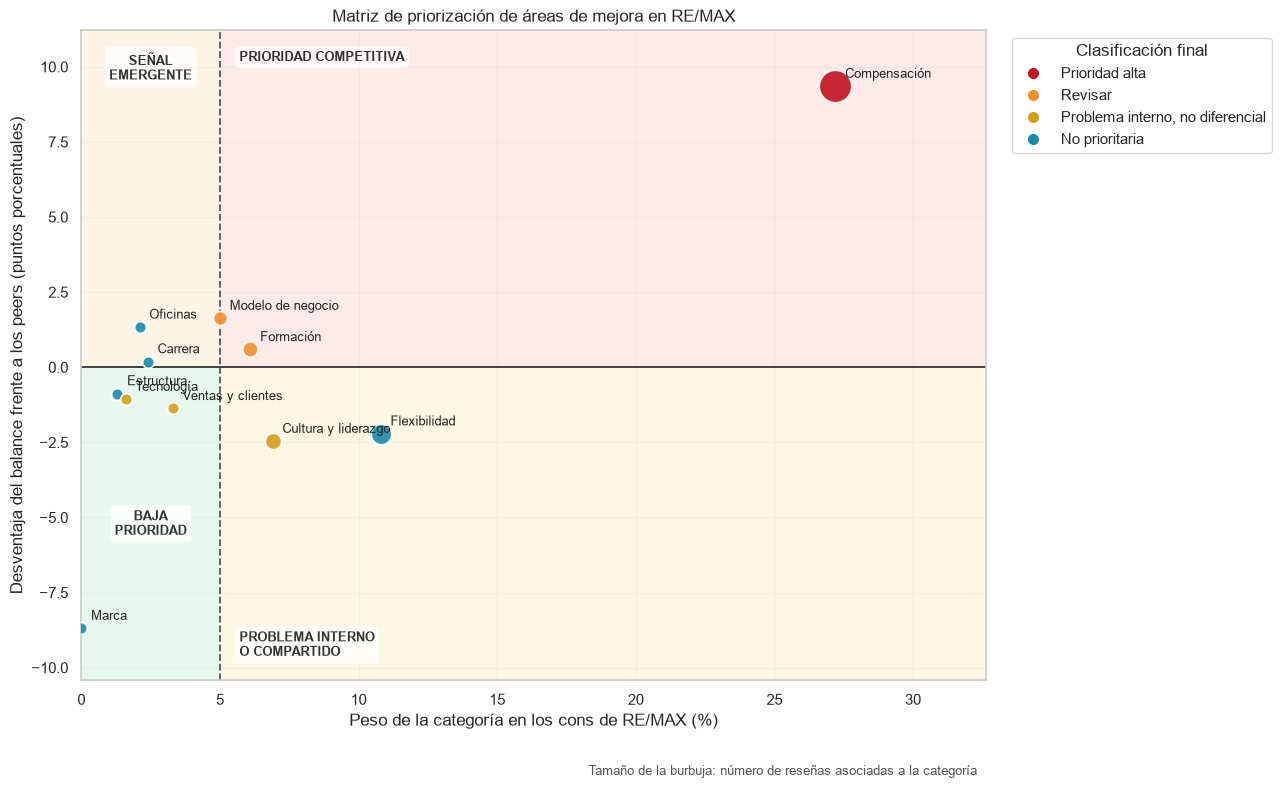

In [48]:
# Visualización de la matriz de priorización

from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

ETIQUETAS_CORTAS = {
    CULTURA: 'Cultura y liderazgo',
    FLEXIBILIDAD: 'Flexibilidad',
    COMPENSACION: 'Compensación',
    FORMACION: 'Formación',
    CARRERA: 'Carrera',
    MARCA: 'Marca',
    VENTAS: 'Ventas y clientes',
    TECNOLOGIA: 'Tecnología',
    OFICINAS: 'Oficinas',
    MODELO_NEGOCIO: 'Modelo de negocio',
    ESTRUCTURA: 'Estructura',
}

# El color de la burbuja recoge la clasificación final,
# después de considerar frecuencia, peers, rating y recomendación.
COLORES_PRIORIDAD = {
    'Prioridad alta': '#C1121F',
    'Revisar': '#F28E2B',
    'Problema interno, no diferencial': '#D4A017',
    'No prioritaria': '#168AAD',
}

# Colores suaves para los cuatro cuadrantes.
COLORES_CUADRANTES = {
    'prioridad_competitiva': '#FADBD8',
    'señal_emergente': '#FDEBD0',
    'problema_interno': '#FCF3CF',
    'baja_prioridad': '#D5F5E3',
}

UMBRAL_PESO = 5
UMBRAL_DESVENTAJA = 0

# Límites dinámicos para que las etiquetas no queden pegadas a los bordes.
x_min = 0
x_max = max(
    30,
    matriz_priorizacion['Peso en cons RE/MAX (%)'].max() * 1.20,
)

y_min = min(
    -10,
    matriz_priorizacion['Desventaja vs. peers'].min() * 1.20,
)

y_max = max(
    10,
    matriz_priorizacion['Desventaja vs. peers'].max() * 1.20,
)

fig, ax = plt.subplots(figsize=(13, 8))

# ------------------------------------------------------------------
# Fondos de los cuatro cuadrantes
# ------------------------------------------------------------------

# Superior izquierdo: poco frecuente, pero peor que los peers.
ax.add_patch(
    Rectangle(
        (x_min, UMBRAL_DESVENTAJA),
        UMBRAL_PESO - x_min,
        y_max - UMBRAL_DESVENTAJA,
        facecolor=COLORES_CUADRANTES['señal_emergente'],
        alpha=0.55,
        zorder=0,
    )
)

# Superior derecho: frecuente y peor que los peers.
ax.add_patch(
    Rectangle(
        (UMBRAL_PESO, UMBRAL_DESVENTAJA),
        x_max - UMBRAL_PESO,
        y_max - UMBRAL_DESVENTAJA,
        facecolor=COLORES_CUADRANTES['prioridad_competitiva'],
        alpha=0.55,
        zorder=0,
    )
)

# Inferior izquierdo: poco frecuente y sin desventaja competitiva.
ax.add_patch(
    Rectangle(
        (x_min, y_min),
        UMBRAL_PESO - x_min,
        UMBRAL_DESVENTAJA - y_min,
        facecolor=COLORES_CUADRANTES['baja_prioridad'],
        alpha=0.55,
        zorder=0,
    )
)

# Inferior derecho: frecuente, pero no peor que los peers.
ax.add_patch(
    Rectangle(
        (UMBRAL_PESO, y_min),
        x_max - UMBRAL_PESO,
        UMBRAL_DESVENTAJA - y_min,
        facecolor=COLORES_CUADRANTES['problema_interno'],
        alpha=0.55,
        zorder=0,
    )
)

# ------------------------------------------------------------------
# Títulos de los cuadrantes
# ------------------------------------------------------------------

estilo_cuadrante = {
    'fontsize': 9,
    'fontweight': 'bold',
    'color': '#333333',
    'bbox': {
        'boxstyle': 'round,pad=0.35',
        'facecolor': 'white',
        'edgecolor': 'none',
        'alpha': 0.75,
    },
}

ax.text(
    UMBRAL_PESO / 2,
    y_max - 0.7,
    'SEÑAL\nEMERGENTE',
    ha='center',
    va='top',
    **estilo_cuadrante,
)

ax.text(
    UMBRAL_PESO + 0.7,
    y_max - 0.7,
    'PRIORIDAD COMPETITIVA',
    ha='left',
    va='top',
    **estilo_cuadrante,
)

ax.text(
    UMBRAL_PESO / 2,
    y_min / 2,
    'BAJA\nPRIORIDAD',
    ha='center',
    va='center',
    **estilo_cuadrante,
)

ax.text(
    UMBRAL_PESO + 0.7,
    y_min + 0.7,
    'PROBLEMA INTERNO\nO COMPARTIDO',
    ha='left',
    va='bottom',
    **estilo_cuadrante,
)

# ------------------------------------------------------------------
# Burbujas de las categorías
# ------------------------------------------------------------------

for categoria, fila in matriz_priorizacion.iterrows():
    clasificacion = fila['Clasificación']

    n_reseñas = fila['n_reseñas']
    tamaño = (
        70
        if pd.isna(n_reseñas)
        else max(70, n_reseñas * 2)
    )

    ax.scatter(
        fila['Peso en cons RE/MAX (%)'],
        fila['Desventaja vs. peers'],
        s=tamaño,
        color=COLORES_PRIORIDAD[clasificacion],
        alpha=0.90,
        edgecolor='white',
        linewidth=1.2,
        zorder=3,
    )

    ax.annotate(
        ETIQUETAS_CORTAS[categoria],
        (
            fila['Peso en cons RE/MAX (%)'],
            fila['Desventaja vs. peers'],
        ),
        xytext=(7, 6),
        textcoords='offset points',
        fontsize=9,
        zorder=4,
    )

# Líneas divisorias.
ax.axvline(
    UMBRAL_PESO,
    color='#555555',
    linestyle='--',
    linewidth=1.3,
    zorder=2,
)

ax.axhline(
    UMBRAL_DESVENTAJA,
    color='#333333',
    linewidth=1.3,
    zorder=2,
)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

ax.set(
    title='Matriz de priorización de áreas de mejora en RE/MAX',
    xlabel='Peso de la categoría en los cons de RE/MAX (%)',
    ylabel='Desventaja del balance frente a los peers (puntos porcentuales)',
)

ax.grid(alpha=0.18, zorder=1)

# ------------------------------------------------------------------
# Leyenda del color de las burbujas
# ------------------------------------------------------------------

elementos_leyenda = [
    Line2D(
        [0],
        [0],
        marker='o',
        linestyle='',
        markersize=9,
        markerfacecolor=color,
        markeredgecolor='white',
        label=clasificacion,
    )
    for clasificacion, color in COLORES_PRIORIDAD.items()
]

ax.legend(
    handles=elementos_leyenda,
    title='Clasificación final',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=True,
)

ax.text(
    0.99,
    -0.13,
    'Tamaño de la burbuja: número de reseñas asociadas a la categoría',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=9,
    color='#555555',
)

plt.tight_layout()

fig.savefig(
    IMAGES_DIR / 'matriz_priorizacion_remax.png',
    dpi=160,
    bbox_inches='tight',
)

plt.show()

In [49]:
matriz_priorizacion.to_csv(
    OUTPUTS_DIR / 'matriz_priorizacion_remax.csv',
)

print(
    OUTPUTS_DIR /
    'matriz_priorizacion_remax.csv'
)

../outputs/matriz_priorizacion_remax.csv


### Interpretación de la matriz de priorización

La matriz combina la frecuencia de cada área en las reseñas negativas de RE/MAX, su diferencia respecto a los peers y su impacto sobre el rating y la recomendación de la empresa.

Los resultados muestran que **compensación, comisiones y costes constituye la principal prioridad de actuación**. Esta categoría representa el 27,2 % de los comentarios negativos de RE/MAX, aparece 9,35 puntos porcentuales más que entre sus competidores y está asociada con un rating 0,21 puntos inferior y una recomendación 5,8 puntos porcentuales menor que la media de la compañía. La convergencia de estos indicadores permite considerarla una debilidad competitiva y no únicamente un problema interno.

El **modelo de negocio y las condiciones de mercado** y la **formación y el acompañamiento inicial** quedan clasificados como áreas que conviene revisar, aunque con menor prioridad. En ambos casos, la desventaja respecto a los peers es reducida y los indicadores de satisfacción no muestran un deterioro generalizado. Por ello, sería conveniente profundizar en estas cuestiones antes de plantear cambios estructurales.

La **cultura y el liderazgo** presentan una situación diferente. RE/MAX recibe proporcionalmente menos críticas sobre esta materia que sus competidores, por lo que constituye una fortaleza relativa. Sin embargo, cuando aparece en una reseña negativa, se asocia con una caída de 0,89 puntos en el rating y de 11,8 puntos porcentuales en la recomendación. Por tanto, no parece un problema generalizado de la organización, pero sí un posible foco de riesgo localizado en determinadas oficinas, equipos o responsables.

Finalmente, la **marca** y la **flexibilidad** aparecen como fortalezas diferenciales. Estas dimensiones pueden aprovecharse en la propuesta de valor al empleado y al asociado, siempre que se comuniquen de forma realista junto con las condiciones económicas y las exigencias propias del modelo de trabajo.

___
## 7. Recomendaciones para Recursos Humanos

A partir del análisis exploratorio, de sentimiento, temático y de la matriz de priorización, se proponen tres líneas de actuación.

### 1. Mejorar la transparencia sobre comisiones, costes e ingresos esperados

RE/MAX debería facilitar, antes de la incorporación, una explicación homogénea y comprensible de las comisiones, cuotas, gastos de oficina, costes comerciales y otros conceptos que afectan al ingreso neto del asociado.

Como medidas concretas se propone:

- Crear un simulador de ingresos netos con distintos escenarios de facturación.
- Entregar un documento normalizado con todos los costes asociados a la actividad.
- Revisar las condiciones y dificultades específicas del primer año.
- Analizar las diferencias entre oficinas para detectar estructuras especialmente desfavorables.
- Incorporar entrevistas de salida que permitan distinguir entre problemas de rentabilidad, falta de ventas y desacuerdo con las condiciones económicas.

Los indicadores de seguimiento podrían ser la rotación durante los primeros 6 y 12 meses, el porcentaje de asociados que declara comprender el modelo económico y el número de salidas relacionadas con comisiones o costes.

### 2. Detectar focos localizados de cultura o liderazgo

La cultura no constituye una desventaja general frente a los peers, pero las reseñas que mencionan problemas culturales o de liderazgo presentan un impacto muy elevado sobre la valoración y la recomendación.

Debido al carácter descentralizado y basado en oficinas o franquicias del modelo de RE/MAX, no debería interpretarse automáticamente como un problema uniforme de toda la organización. Se recomienda:

- Realizar encuestas breves y periódicas segmentadas por oficina y responsable.
- Establecer canales confidenciales para comunicar problemas de liderazgo.
- Comparar rotación, satisfacción y recomendación entre oficinas.
- Ofrecer formación en liderazgo, comunicación y gestión de conflictos a brokers y responsables.
- Intervenir prioritariamente en las oficinas que acumulen resultados negativos.

El objetivo sería detectar problemas concretos antes de que se conviertan en una percepción general de la marca empleadora.

### 3. Reforzar una propuesta de valor realista y un onboarding estructurado

La marca y la flexibilidad son fortalezas diferenciales de RE/MAX y pueden utilizarse para atraer y fidelizar talento. No obstante, deben presentarse junto con información realista sobre la autonomía, la necesidad de generar negocio, los costes de la actividad y la variabilidad de los ingresos.

Se propone desarrollar un programa de incorporación de 90 días que combine:

- Formación comercial y operativa.
- Mentorización durante los primeros meses.
- Explicación práctica del modelo económico.
- Objetivos progresivos y realistas.
- Seguimiento de la adaptación del nuevo asociado.
- Comunicación de las ventajas de la marca, la red y la flexibilidad.

Esta actuación permitiría aprovechar las fortalezas identificadas y, al mismo tiempo, reducir posibles diferencias entre las expectativas iniciales y la experiencia real.

In [50]:
# Resumen ejecutivo de recomendaciones para RRHH
recomendaciones_rrhh = pd.DataFrame([
    {
        'prioridad': 1,
        'area': 'Compensación, comisiones y costes',
        'diagnostico': (
            'Principal debilidad competitiva: elevada frecuencia y efecto '
            'negativo sobre rating y recomendación.'
        ),
        'accion_principal': (
            'Estandarizar la información económica, crear un simulador de '
            'ingresos netos y revisar las condiciones del primer año.'
        ),
        'indicadores': (
            'Rotación a 6/12 meses; comprensión del modelo económico; '
            'salidas relacionadas con costes o comisiones.'
        )
    },
    {
        'prioridad': 2,
        'area': 'Cultura y liderazgo',
        'diagnostico': (
            'Fortaleza relativa frente a los peers, pero con impacto muy '
            'negativo cuando el problema aparece.'
        ),
        'accion_principal': (
            'Detectar oficinas o responsables con resultados anómalos mediante '
            'encuestas, canales confidenciales y análisis segmentado.'
        ),
        'indicadores': (
            'Satisfacción y recomendación por oficina; rotación; incidencias '
            'y tiempo de resolución.'
        )
    },
    {
        'prioridad': 3,
        'area': 'Propuesta de valor y onboarding',
        'diagnostico': (
            'Marca y flexibilidad como fortalezas, con necesidad de ajustar '
            'expectativas sobre costes, autonomía y generación de negocio.'
        ),
        'accion_principal': (
            'Implantar un onboarding de 90 días con formación, mentoría, '
            'seguimiento y explicación del modelo económico.'
        ),
        'indicadores': (
            'Finalización de la formación; adaptación inicial; tiempo hasta '
            'la primera operación; rotación temprana.'
        )
    }
])

display(recomendaciones_rrhh)



,prioridad,area,diagnostico,accion_principal,indicadores
0,1,"Compensación, comisiones y costes",Principal debilidad competitiva: elevada frecu...,"Estandarizar la información económica, crear u...",Rotación a 6/12 meses; comprensión del modelo ...
1,2,Cultura y liderazgo,"Fortaleza relativa frente a los peers, pero co...",Detectar oficinas o responsables con resultado...,Satisfacción y recomendación por oficina; rota...
2,3,Propuesta de valor y onboarding,"Marca y flexibilidad como fortalezas, con nece...",Implantar un onboarding de 90 días con formaci...,Finalización de la formación; adaptación inici...


In [51]:
ruta_recomendaciones = OUTPUTS_DIR / 'recomendaciones_rrhh_remax.csv'

recomendaciones_rrhh.to_csv(
    ruta_recomendaciones,
    index=False,
    encoding='utf-8-sig'
)

print(f'Recomendaciones guardadas en: {ruta_recomendaciones.resolve()}')

Recomendaciones guardadas en: /Users/jobdelgadoiniesta/Documents/EVOLVE/06_DeepLearning/proyecto_modular_deeplearning/outputs/recomendaciones_rrhh_remax.csv


## 8. Limitaciones del análisis

Los resultados deben interpretarse teniendo en cuenta las siguientes limitaciones:

- Las reseñas de Glassdoor son voluntarias y pueden no representar a toda la plantilla o red de asociados.
- Los datos agrupan oficinas, países, funciones y modalidades laborales diferentes.
- En una red de franquicias, una experiencia negativa puede depender de una oficina o responsable concreto y no de toda la organización.
- La condición de empleado actual o antiguo no permite conocer el momento exacto de la salida ni demostrar qué la provocó.
- La diferencia entre empleados actuales y antiguos puede reflejar tanto la experiencia posterior de quienes salieron como la evolución de la propia empresa.
- Las comparaciones temporales utilizan la fecha de publicación de la reseña, que no necesariamente coincide con el periodo en el que se produjo la experiencia descrita.
- La muestra fue limitada a un máximo de 1.000 reseñas por empresa, mientras que algunas compañías disponían de menos observaciones.
- Los modelos de sentimiento y tópicos pueden cometer errores, especialmente ante negaciones, ironía, textos ambiguos o comentarios que contienen varias ideas.
- La agrupación de tópicos en categorías de negocio incorpora una interpretación manual.
- El análisis identifica asociaciones, pero no permite establecer relaciones causales ni afirmar que una categoría concreta sea por sí sola el motivo de abandono.

## 9. Conclusión

RE/MAX presenta una valoración global favorable y superior a la media de los peers analizados. La marca, la flexibilidad y determinados aspectos culturales constituyen ventajas relevantes que pueden reforzar su posicionamiento como empleador y como red para profesionales inmobiliarios.

La principal debilidad identificada se concentra en la compensación, las comisiones y los costes asociados al modelo de trabajo. Se trata del área con mayor frecuencia entre los comentarios negativos, la mayor desventaja frente a los competidores y un efecto desfavorable sobre el rating y la recomendación.

La cultura y el liderazgo no aparecen como una debilidad competitiva general, pero sí como un riesgo de elevada intensidad cuando se producen experiencias negativas. Esto aconseja realizar un seguimiento segmentado por oficina, equipo y responsable.

La menor valoración de los antiguos empleados puede responder a diferentes mecanismos: experiencias negativas previas a la salida, ampliación de sus referencias al conocer otros modelos de trabajo o exposición a procesos organizativos anteriores. Con los datos disponibles no es posible separar estos efectos ni atribuirles causalidad.

En consecuencia, la estrategia de Recursos Humanos debería combinar una mayor transparencia económica, la detección temprana de focos locales de liderazgo y un proceso de incorporación que comunique de forma equilibrada tanto las ventajas como las exigencias del modelo RE/MAX.